[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/notebooks/RO/capitol7_notebook_seminar.ipynb)

# Modelarea piețelor financiare — Seminarul 7: Value-at-Risk (VaR) și Expected Shortfall

*Notebook de seminar. Daniel Traian Pele, Antoaneta Amza, Academia de Studii Economice din București.*

- Problemele **[Rezolvat]** conțin rezolvarea completă; problemele **[Propus]** le rezolvați individual.
- Partea A: derivări (A1–A8); Partea B: estimare și inferență (B1–B7); Partea C: critica unui răspuns Artificial Intelligence (AI) (C1) și proiecte deschise (C2, C3).
- Seminarul are loc înaintea cursului 7; slide-urile încep cu o scurtă secțiune introductivă (VaR și Expected Shortfall (ES), coerență, simulare istorică și filtrată, orizonturi).
- **La seminar**: A1–A4, B1, B2, B3, C1. **După curs**: B4 (teoria valorilor extreme), A5 și B5 (contribuții la risc); celelalte secțiuni sînt extensii opționale.

> Rezolvările se discută la seminar.

> **În Google Colab, salvați întîi o copie proprie.**
> Folosiți **File → Save a copy in Drive** și lucrați în acea copie. Fișierele CSV și graficele create în sesiune sînt temporare; setați `SAVE_TO_DRIVE = True` în celula următoare pentru a le păstra în Drive.

In [ ]:
# Opțional, numai în Colab: păstrați fișierele create în Google Drive
SAVE_TO_DRIVE = False

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/MFM/Chapter_7'
    os.makedirs(OUT_DIR, exist_ok=True)
    os.chdir(OUT_DIR)
print('Folderul de ieșire este definit prin OUT_DIR; SAVE_TO_DRIVE activează păstrarea în Drive.')

Folderul de ieșire este definit prin OUT_DIR; SAVE_TO_DRIVE activează păstrarea în Drive.


In [ ]:
# Pe Colab, instalați întîi arch: !pip install arch
import os
import re
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, integrate, signal
try:
    from arch import arch_model
except ModuleNotFoundError as exc:
    if exc.name != 'arch':
        raise
    import subprocess
    import sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', 'arch'], check=True)
    from arch import arch_model
import warnings
warnings.filterwarnings('ignore')

## Stil și funcții ajutătoare

In [ ]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Brand colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
Teal     = '#17A2B8'
METHOD_COL = {'HS': MainBlue, 'Normal': Orange, 'Student-t': Forest, 'Cornish-Fisher': Purple, 'EVT (GPD)': IDAred}

def _reviewed_layout(fig,name):
    targets={'ch7_caviar','ch7_basel','ch7_precision','ch7_crk_table6','ch7_sem_b4_clusters','ch7_sem_c3_design','ch7_sem_a7_ru','ch7_sem_b3_boot','ch7_sem_b5_rp','ch7_sem_b6_methods'}
    if name not in targets:return False
    fig.set_size_inches(5.67,2.65)
    handles=[];labels=[]
    for ax in fig.axes:
        h,l=ax.get_legend_handles_labels()
        for hi,li in zip(h,l):
            if li not in labels:handles.append(hi);labels.append(li)
        ax.tick_params(labelsize=8)
        ax.xaxis.label.set_fontsize(9);ax.yaxis.label.set_fontsize(9)
        ax.title.set_fontsize(10)
        for t in ax.texts:t.set_fontsize(8)
        if ax.get_legend():ax.get_legend().remove()
    for leg in list(fig.legends):leg.remove()
    ax=fig.axes[0];ncol=2;legsize=8
    if name=='ch7_caviar':
        for line in ax.lines:
            if line.get_label().startswith('CAViaR'):line.set_zorder(5);line.set_linestyle('--');line.set_linewidth(1.2)
            elif line.get_label().startswith('FHS'):line.set_alpha(.65);line.set_linewidth(.8)
        ax.set_title('S&P 500: out-of-sample VaR 1%, 2016–2026',fontsize=10)
        labels=[('Daily loss (positive part)' if x.startswith('Daily loss') else 'CAViaR: fit 2000–2015' if x.startswith('CAViaR') else 'FHS: refit each January') for x in labels];ncol=3;legsize=7.5
        fig.subplots_adjust(left=.10,right=.99,top=.84,bottom=.25)
    elif name=='ch7_basel':
        ax.set_title('Historical simulation: ES/VaR ratios above bars',fontsize=10)
        ax.set_ylabel('Daily loss (%)');ax.margins(y=.22)
        fig.subplots_adjust(left=.10,right=.99,top=.84,bottom=.26)
    elif name=='ch7_precision':
        ax.set_title('S&P 500: 95% confidence intervals',fontsize=10)
        ax.set_xlabel('Daily loss (%); black tick = estimate',fontsize=9)
        ax.set_xlim(1.4,4.9)
        for t in ax.texts:t.set_visible(False)
        labels=['Asymptotic i.i.d.','Asymptotic HAC','i.i.d. bootstrap','Block bootstrap (20 days)']
        fig.subplots_adjust(left=.20,right=.99,top=.82,bottom=.31)
    elif name=='ch7_crk_table6':
        ax.set_title('S&P 500 VaR 1%: relative forecast errors',fontsize=10)
        ax.set_ylabel('Relative RMSFE (log scale)',fontsize=9)
        for t in ax.texts:
            if t.get_text()=='0.024':t.set_bbox(dict(facecolor='white',edgecolor='none',pad=.7))
            if 'Deep neural' in t.get_text():t.set_text('Deep neural networks')
            if 'Linear quantile' in t.get_text():t.set_text('Linear quantile regression = 1');t.set_fontsize(7.5)
        labels=[x.replace('Predictors: ','') for x in labels];ncol=4
        fig.subplots_adjust(left=.12,right=.99,top=.84,bottom=.32)
    elif name=='ch7_sem_b4_clusters':
        ax.set_position([.11,.66,.87,.19]);fig.axes[1].set_position([.11,.28,.36,.17]);fig.axes[2].set_position([.64,.28,.34,.17])
        import matplotlib.dates as mdates
        ax.xaxis.set_major_locator(mdates.YearLocator(5))
        ax.set_title(ax.get_title().replace('BET losses above','BET: above'),fontsize=9)
        fig.axes[2].set_title('VaR vs threshold',fontsize=9)
        fig.axes[2].set_xlabel('Exceedance share (%)',fontsize=8)
        labels=['Exceedances (alternating clusters)','Cluster maximum','Mean excess','GPD VaR 0.1%'];legsize=7.5
    elif name=='ch7_sem_c3_design':
        ax.set_position([.11,.64,.87,.21]);fig.axes[1].set_position([.10,.20,.89,.26])
        ax.set_title('S&P 500: tuning and held-out evaluation',fontsize=10)
        labels=[x.replace('Cross-validation: 20 random test days, each with ±5 neighbouring days excluded','20 CV test days; exclude ±5 neighbours') for x in labels]
        tl=fig.axes[1]
        for t in tl.texts:
            text=t.get_text()
            if text in ['$t$','$t+1$','$t+10$']:t.set_y(.34);t.set_va('top')
            elif 'cumulative' in text:t.set_y(-.14);t.set_fontsize(8)
            elif 'Alignment' in text:t.set_y(1.04);t.set_fontsize(9)
            elif 'target:' in text:t.set_y(.80);t.set_fontsize(8)
        for line in tl.lines:
            if len(line.get_ydata())==4:line.set_ydata([.07,.01,.01,.07])
        legsize=7.5
    elif name in {'ch7_sem_b3_boot','ch7_sem_b5_rp'}:
        fig.set_size_inches(5.67,1.45)
        fig.subplots_adjust(left=.10,right=.99,top=.94,bottom=.49)
        ax.tick_params(labelsize=8)
        ax.xaxis.label.set_fontsize(8)
        if name=='ch7_sem_b3_boot':
            labels=[x.replace(' (unconditional)','').replace(' bootstrap forecasts',' bootstrap draws') for x in labels]
        else:
            labels=[x.replace('Share of historical ES 2.5% at risk parity','ES 2.5% share') for x in labels];ncol=3
        legsize=7.5
    elif name=='ch7_sem_b6_methods':
        fig.set_size_inches(5.67,1.8)
        fig.subplots_adjust(left=.08,right=.99,top=.84,bottom=.34,wspace=.55)
        for a in fig.axes:a.set_xlabel('')
        fig.text(.54,.15,'Tail probability of VaR',ha='center',fontsize=8)
        ncol=3;legsize=7.5
    elif name=='ch7_sem_a7_ru':
        fig.subplots_adjust(left=.11,right=.98,top=.94,bottom=.27)
        ax.tick_params(labelsize=10)
        ax.xaxis.label.set_fontsize(10);ax.yaxis.label.set_fontsize(10)
        for t in ax.texts:
            t.set_fontsize(10)
            if 'minimum' in t.get_text():t.set_bbox(dict(facecolor='white',edgecolor='none',pad=.8))
        legsize=9
    fig.legend(handles,labels,loc='lower center',bbox_to_anchor=(.53,-.015),ncol=ncol,frameon=False,fontsize=legsize,handlelength=1.4,columnspacing=.9)
    return True

HERE = '.'
SEED = 42
ORDER = ['sp500', 'bet', 'btc', 'eurron', 'gold']
METHODS = ['HS', 'Normal', 'Student-t', 'Cornish-Fisher', 'EVT (GPD)']
B_BOOT = 2000


def save_fig(name):
    """Save the figure as a transparent PDF and PNG in the current folder."""
    _reviewed_layout(plt.gcf(), name)
    plt.savefig(f'{name}.pdf', bbox_inches='tight', transparent=True)
    plt.savefig(f'{name}.png', bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)



import tempfile
# cu SAVE_TO_DRIVE = True (celula de la început), tabelele și graficele se păstrează în OUT_DIR; altfel într-un folder temporar
KEEP = bool(globals().get('SAVE_TO_DRIVE', False))
HERE = globals().get('OUT_DIR', '.') if KEEP else tempfile.gettempdir()


def save_fig(name):
    """Afișează figura; o salvează ca PNG în OUT_DIR cînd SAVE_TO_DRIVE este activ."""
    _reviewed_layout(plt.gcf(), name)
    if KEEP:
        plt.savefig(os.path.join(HERE, name + '.png'), dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

## Date

- Închideri zilnice pînă la 18 septembrie 2026: S&P 500, BET, Bitcoin, EUR/RON (cursul de referință Banca Națională a României (BNR)), aur (USD pe uncie troy).
- Indici bursieri: doar zilele lucrătoare; eliminăm înregistrările de sărbătoare (închidere neschimbată, volum zero), păstrăm închiderile neschimbate reale; aur: doar zilele lucrătoare; Bitcoin: 7 zile pe săptămînă.
- Randament log zilnic în %, $r_t = 100(\ln P_t - \ln P_{t-1})$; pierderea log $L = -r$; Valorile pozitive ale VaR și ES exprimă pierderi. În unități monetare, o pierdere log $L$ corespunde la $V(1 - e^{-L/100})$.

In [ ]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
# use the local copy of the course data when the notebook runs inside the repository
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')
END = '2026-09-18'

# name -> (symbol, label, type, start date)
MARKETS = {
    'sp500':  ('GSPC.INDX',    'S&P 500',                  'index',  '2000-01-01'),
    'bet':    ('BET',          'BET',                      'index',  '2000-01-01'),
    'btc':    ('BTC-USD.CC',   'Bitcoin',                  'crypto', '2014-09-17'),
    'eurron': ('REF:EUR',      'EUR/RON (reference rate)', 'fx',     '2005-07-01'),
    'gold':   ('XAUUSD.FOREX', 'Gold (XAU/USD)',           'fx',     '2000-01-01'),
}
# portfolio assets (prices aligned on common days)
ASSETS = {
    'SPY': ('SPY.US', 'adjusted_close'), 'TLT': ('TLT.US', 'adjusted_close'), 'GLD': ('GLD.US', 'adjusted_close'),
    'BTC': ('BTC-USD.CC', 'close'),
    'TLV': ('TLV.RO', 'adjusted_close'), 'SNP': ('SNP.RO', 'adjusted_close'), 'BRD': ('BRD.RO', 'adjusted_close'),
    'TGN': ('TGN.RO', 'adjusted_close'), 'SNG': ('SNG.RO', 'adjusted_close'), 'SNN': ('SNN.RO', 'adjusted_close'),
    'EL': ('EL.RO', 'adjusted_close'), 'FP': ('FP.RO', 'adjusted_close'), 'TEL': ('TEL.RO', 'adjusted_close'),
}
LABELS = {k: v[1] for k, v in MARKETS.items()}

_CACHE = {}


def read_market(symbol):
    """Read the daily price series of one symbol (local copy of the course data, else from GitHub)."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()


def read_reference_rate(currency='EUR', start='2005-07-01', end=END):
    """Official RON reference rate (annual BNR XML archives)."""
    key = (currency, start, end)
    if key in _CACHE:
        return _CACHE[key]
    rows = []
    for y in range(int(start[:4]), int(end[:4]) + 1):
        url = f'https://curs.bnr.ro/files/xml/years/nbrfxrates{y}.xml'
        xml = urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'Mozilla'}),
                                     timeout=60).read().decode()
        for d, body in re.findall(r'<Cube date="([\d-]+)">(.*?)</Cube>', xml, re.S):
            m = re.search(rf'<Rate currency="{currency}">([\d.]+)</Rate>', body)
            if m:
                rows.append((d, float(m.group(1))))
    s = pd.DataFrame(rows, columns=['date', 'close']).drop_duplicates('date').set_index('date')['close']
    s.index = pd.to_datetime(s.index)
    _CACHE[key] = s.sort_index().loc[start:end]
    return _CACHE[key]


def load_close(name, start=None, end=END):
    """Daily price, cleaned according to the chapter conventions."""
    symbol, _, kind, start0 = MARKETS[name]
    start = start or start0
    if symbol.startswith('REF:'):
        return read_reference_rate(symbol.split(':')[1], start=start, end=end).rename(name)
    d = read_market(symbol).loc[start:end]
    d = d[d['close'] > 0].dropna(subset=['close'])
    if kind != 'crypto':
        d = d[d.index.dayofweek < 5]          # no weekend quotes
    s = d['close']
    if kind == 'index' and 'volume' in d:
        # drop holidays filled with the previous price: unchanged close and zero/missing volume
        s = s[~((s.diff() == 0) & (d['volume'].fillna(0) <= 0))]
    return s.rename(name)


def log_returns(name, start=None, end=END):
    """Log returns on the series' own calendar."""
    return np.log(load_close(name, start, end)).diff().dropna().rename(name)


def periods_per_year(r):
    """Actual frequency: average number of observations per calendar year."""
    return len(r) / ((r.index[-1] - r.index[0]).days / 365.25)


def asset_price(key, end=END):
    symbol, col = ASSETS[key]
    s = read_market(symbol)[col].loc[:end]
    s = s[s > 0].dropna()
    if key != 'BTC':
        s = s[s.index.dayofweek < 5]
    return s.rename(key)


def joint_returns(keys, start=None, end=END):
    """Log returns for several assets: align the PRICES on common days first, then compute returns."""
    p = pd.concat([asset_price(k, end) for k in keys], axis=1, join='inner').dropna()
    if start:
        p = p.loc[start:]
    return np.log(p).diff().dropna()


# daily log returns in %, loss L = -r
rets = {k: 100 * log_returns(k) for k in MARKETS}
loss = {k: -v for k, v in rets.items()}
for k in ORDER:
    print(f'{LABELS[k]:26s}', rets[k].index[0].date(), '->', rets[k].index[-1].date(), len(rets[k]), 'obs')

S&P 500                    2000-01-04 -> 2026-09-18 6717 obs
BET                        2000-01-06 -> 2026-09-18 6670 obs
Bitcoin                    2014-09-18 -> 2026-09-18 4384 obs
EUR/RON (reference rate)   2005-07-05 -> 2026-09-18 5352 obs
Gold (XAU/USD)             2000-01-04 -> 2026-09-18 6956 obs


## Măsuri de risc

- VaR și ES prin patru metode: istoric, distribuția Normală, Student-$t$, Cornish–Fisher (`hs_var_es`, `normal_var_es`, `t_var_es`, `cf_var_es`).
- Convenția istorică: VaR = cuantila empirică interpolată de ordin $(1-\alpha)$ a pierderii; ES = media pierderilor mai mari sau egale cu ea (circa $n\alpha$ pierderi; înlocuirea exactă în integrală ar pondera pierderea de la frontieră cu $n\alpha - \lfloor n\alpha \rfloor$).
- Depășiri de prag: estimarea Generalised Pareto Distribution (GPD), VaR și ES din GPD, erori standard, excesul mediu (`gpd_fit`, `gpd_var_es`, `gpd_se`, `mean_excess`).
- Filtrare prin modelul Autoregressive de ordin 1, AR(1), și modelul Generalised Autoregressive Conditional Heteroskedasticity, GARCH(1,1), simulare istorică filtrată și Extreme Value Theory (EVT) condiționată (`garch_filter`, `garch_next`, `fhs_mc`, `rolling_conditional`).

In [ ]:
def hs_var_es(L, alpha):
    """Historical simulation: VaR alpha = empirical (1 - alpha)-quantile of the loss; ES = mean of the losses beyond it."""
    L = np.asarray(L)
    v = np.quantile(L, 1 - alpha)
    return v, L[L >= v].mean()


def normal_var_es(L, alpha):
    """Distributia Normala: VaR = -mu_X + sigma z_{1-alpha}, ES = -mu_X + sigma phi(z_alpha)/alpha (mu_L = -mu_X)."""
    mu, s = np.mean(L), np.std(L, ddof=1)
    z = stats.norm.ppf(1 - alpha)
    return mu + s * z, mu + s * stats.norm.pdf(z) / alpha


def t_fit(L):
    """Student-t with location and scale, fitted by maximum likelihood."""
    return stats.t.fit(np.asarray(L))


def t_var_es(L, alpha, params=None):
    """Student-t on losses: VaR = m + s t_{1-alpha}, ES = m + s g(t_alpha)/alpha (nu + t_alpha^2)/(nu - 1)."""
    nu, m, s = params if params is not None else t_fit(L)
    q = stats.t.ppf(1 - alpha, nu)
    return m + s * q, m + s * stats.t.pdf(q, nu) / alpha * (nu + q ** 2) / (nu - 1)


def cf_quantile(z, S, K):
    """Standardised Cornish-Fisher quantile: z = Normal quantile, S = skewness, K = excess kurtosis."""
    return z + (z ** 2 - 1) * S / 6 + (z ** 3 - 3 * z) * K / 24 - (2 * z ** 3 - 5 * z) * S ** 2 / 36


def cf_var_es(L, alpha):
    """Cornish-Fisher on returns X = -L: VaR = -(mu_X + sigma z~_alpha); ES = mean of VaR_u for u in (0, alpha)."""
    X = -np.asarray(L)
    mu, s = X.mean(), X.std(ddof=1)
    S, K = stats.skew(X), stats.kurtosis(X)
    var = -(mu + s * cf_quantile(stats.norm.ppf(alpha), S, K))
    es = -integrate.quad(lambda u: mu + s * cf_quantile(stats.norm.ppf(u), S, K), 0, alpha, limit=200)[0] / alpha
    return var, es


def gpd_fit(L, tail=0.05):
    """POT: the threshold u leaves the share tail of the losses above it; GPD fitted by maximum likelihood to the excesses."""
    L = np.asarray(L)
    u = np.quantile(L, 1 - tail)
    ex = L[L > u] - u
    xi, _, beta = stats.genpareto.fit(ex, floc=0)
    return dict(u=u, xi=xi, beta=beta, nu=len(ex), n=len(L))


def gpd_var_es(fit, alpha):
    """VaR and ES at tail probability alpha from the GPD tail (Smith-type estimator)."""
    u, xi, beta, nu, n = fit['u'], fit['xi'], fit['beta'], fit['nu'], fit['n']
    var = u + beta / xi * (((n / nu) * alpha) ** (-xi) - 1)
    return var, var / (1 - xi) + (beta - xi * u) / (1 - xi)


def gpd_se(fit):
    """Asymptotic standard errors of the GPD maximum likelihood estimates (xi > -1/2)."""
    xi, beta, nu = fit['xi'], fit['beta'], fit['nu']
    return np.sqrt((1 + xi) ** 2 / nu), np.sqrt(2 * beta ** 2 * (1 + xi) / nu)


def mean_excess(L, us):
    """Mean excess function e(u) = E[L - u | L > u] on a grid of thresholds."""
    L = np.asarray(L)
    return np.array([(L[L > u] - u).mean() for u in us]), np.array([(L > u).sum() for u in us])


def garch_backcast(x):
    """Starting value of the variance (as in arch): EWMA mean (0.94) of the first 75 squared residuals
    of an AR(1) fitted by OLS, computed ONLY on the estimation sample x."""
    x = np.asarray(x, float)
    X = np.column_stack([np.ones(len(x) - 1), x[:-1]])
    e = x[1:] - X @ np.linalg.lstsq(X, x[1:], rcond=None)[0]
    tau = min(75, len(e))
    w = 0.94 ** np.arange(tau)
    return float((w / w.sum()) @ e[:tau] ** 2)


def robust_garch_fit(r, last_obs=None, audit=None):
    """Same Normal QML objective; allow up to 2000 SLSQP iterations per candidate.

    Refined projected starts use ftol=1e-10. Fixed scales and starts use only the estimation window. A large likelihood
    advantage from a near-feasible rejected candidate is an explicit diagnostic
    failure, never a silent fallback to a poorly optimized accepted candidate.
    """
    import math
    import warnings
    import numpy as np
    from arch import arch_model
    from arch.utility.exceptions import StartingValueWarning
    spec = dict(mean='AR', lags=1, vol='GARCH', p=1, q=1,
                dist='normal', rescale=False)
    base = arch_model(r, **spec)
    best = None
    rows = []
    expected_nobs = None
    expected_names = None
    for scale in (1.0, 10.0, 100.0):
        model = arch_model(scale * r, **spec)
        starts = [('default', None)]
        for mode, start in starts:
            try:
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter('always')
                    options = {'maxiter': 2000}
                    if mode.startswith('refine'):
                        options['ftol'] = 1e-10
                    fit = model.fit(disp='off', last_obs=last_obs,
                                    starting_values=start, options=options)
            except Exception as exc:
                if scale == 1 and mode == 'default':
                    raise
                rows.append(dict(scale=scale, start=mode, accepted=False,
                                 error=f'{type(exc).__name__}: {exc}'))
                continue
            p = fit.params.copy()
            if expected_names is None:
                expected_names = list(p.index)
            if list(p.index) != expected_names:
                raise RuntimeError('GARCH parameter labels or order changed across scales')
            if len(starts) < 5 and np.isfinite(p).all() and p.iloc[3] + p.iloc[4] > 1:
                # Only the initial point is projected. The fitted parameter space is unchanged.
                seed = p.copy()
                if 0 <= seed.iloc[3] <= 1:
                    seed.iloc[4] = max(0.0, np.nextafter(1.0 - seed.iloc[3], 0.0))
                    starts.append(('projected' if mode == 'default' else f'refine{len(starts)}', seed))
            p.iloc[0] /= scale
            p.iloc[2] /= scale ** 2
            try:
                fixed = base.fix(p, last_obs=last_obs)
            except Exception as exc:
                if scale == 1 and mode == 'default':
                    raise
                rows.append(dict(scale=scale, start=mode, accepted=False,
                                 error=f'{type(exc).__name__}: {exc}'))
                continue
            ll = float(fixed.loglikelihood)
            equivalent_ll = float(fit.loglikelihood + fit.nobs * math.log(scale))
            if expected_nobs is None:
                expected_nobs = fit.nobs
            violation = max(0., float(p.iloc[3] + p.iloc[4] - 1))
            ignored_start = any(issubclass(w.category, StartingValueWarning) for w in caught)
            accepted = bool(fit.convergence_flag == 0 and not ignored_start
                            and np.isfinite(p).all() and np.isfinite(ll)
                            and p.iloc[2] > 0 and p.iloc[3] >= 0 and p.iloc[4] >= 0
                            and violation <= 1e-10
                            and fit.nobs == fixed.nobs == expected_nobs
                            and abs(ll - equivalent_ll) <= 1e-7)
            row = dict(scale=scale, start=mode, flag=int(fit.convergence_flag),
                       accepted=accepted, ll=ll, likelihood_equivalence_error=ll-equivalent_ll,
                       nobs=int(fit.nobs), constraint_violation=violation,
                       params=p.to_dict(), warnings=[str(w.message) for w in caught])
            rows.append(row)
            # Differences below 1e-6 are treated as numerical ties, in fixed candidate order.
            if accepted and (best is None or ll > best[0] + 1e-6):
                best = (ll, p, len(rows)-1)
    if audit is not None:
        audit.update(candidates=rows, selected=None if best is None else best[2])
    if best is None:
        raise RuntimeError('No converged feasible Normal AR(1)-GARCH(1,1) candidate')
    suspect = [row for row in rows if not row['accepted']
               and row.get('flag') in (0, 8)
               and row.get('constraint_violation', float('inf')) <= 1e-6
               and np.isfinite(row.get('ll', float('nan')))
               and row['ll'] > best[0] + 1.0]
    if suspect:
        if audit is not None:
            audit['suspect_rejected_advantage'] = suspect
        raise RuntimeError('Near-feasible GARCH candidate has materially higher likelihood; numerical review required')
    return best[1]

def garch_filter(r, params=None, last_obs=None):
    """AR(1)-GARCH(1,1) by Normal QML (Chapter 5); r in %.
    Parameters are estimated on the data before last_obs; the filter is causal: mu_t and sigma_t use
    only r_1..r_{t-1}, and the starting variance comes only from the estimation sample.
    Returns the parameters and the series mu_t, sigma_t for the whole sample."""
    if params is None:
        am = arch_model(r, mean='AR', lags=1, vol='GARCH', p=1, q=1, dist='normal', rescale=False)
        params = robust_garch_fit(r, last_obs=last_obs)
    est = r if last_obs is None else r.loc[r.index < pd.Timestamp(last_obs)]
    c, phi, om, al, be = params.values[:5]
    x = np.asarray(r, float)
    mu = np.full(len(x), np.nan)
    mu[1:] = c + phi * x[:-1]
    e = x - mu
    u = np.empty(len(x) - 1)
    u[0] = om + (al + be) * garch_backcast(np.asarray(est, float))
    u[1:] = om + al * e[1:-1] ** 2
    s2 = np.full(len(x), np.nan)
    s2[1:] = signal.lfilter([1.0], [1.0, -be], u)
    return params, pd.Series(mu, index=r.index), pd.Series(np.sqrt(s2), index=r.index)


def garch_next(r, params):
    """Conditional mean and volatility for the day after the last observation."""
    c, phi, om, al, be = params.values[:5]
    _, mu, sig = garch_filter(r, params)
    e = r.iloc[-1] - mu.iloc[-1]
    return c + phi * r.iloc[-1], np.sqrt(om + al * e ** 2 + be * sig.iloc[-1] ** 2)


def fhs_mc(r, params, z, h, n_paths=100_000, seed=42):
    """FHS Monte Carlo: h-day AR(1)-GARCH(1,1) paths with resampled standardised residuals.
    Returns the cumulative h-day losses (in %, log returns)."""
    rng = np.random.default_rng(seed)
    c, phi, om, al, be = params.values[:5]
    _, mu, sig = garch_filter(r, params)
    r_prev = np.full(n_paths, r.iloc[-1])
    e_prev = np.full(n_paths, r.iloc[-1] - mu.iloc[-1])
    s2_prev = np.full(n_paths, sig.iloc[-1] ** 2)
    tot = np.zeros(n_paths)
    for _ in range(h):
        s2 = om + al * e_prev ** 2 + be * s2_prev
        e = np.sqrt(s2) * rng.choice(z, n_paths)
        r_new = c + phi * r_prev + e
        tot += r_new
        r_prev, e_prev, s2_prev = r_new, e, s2
    return -tot


def rolling_conditional(r, first_year, window_hs=500, alpha=0.01, tail_evt=0.10):
    """Day-by-day conditional VaR/ES: AR(1)-GARCH parameters re-estimated at the start of every year
    on all earlier data; FHS and conditional EVT use the earlier standardised residuals.
    For comparison: HS on a rolling window of window_hs days. No look-ahead bias."""
    out = []
    L = -r
    for y in range(first_year, r.index[-1].year + 1):
        est = r.loc[:f'{y - 1}-12-31']
        params, mu, sig = garch_filter(r, last_obs=f'{y}-01-01')
        z = ((est - mu.loc[est.index]) / sig.loc[est.index]).dropna()
        nz = -z.values
        fz = gpd_fit(nz, tail_evt)
        q_fhs, q_evt_v = np.quantile(nz, 1 - alpha), gpd_var_es(fz, alpha)[0]
        es_fhs = nz[nz >= q_fhs].mean()
        es_evt = gpd_var_es(fz, alpha)[1]
        days = r.loc[f'{y}-01-01':f'{y}-12-31'].index
        for d in days:
            i = r.index.get_loc(d)
            past = L.iloc[max(0, i - window_hs):i]
            out.append((d, L.loc[d], -mu.loc[d] + sig.loc[d] * q_fhs, -mu.loc[d] + sig.loc[d] * es_fhs,
                        -mu.loc[d] + sig.loc[d] * q_evt_v, -mu.loc[d] + sig.loc[d] * es_evt,
                        -mu.loc[d] + sig.loc[d] * stats.norm.ppf(1 - alpha), np.quantile(past, 1 - alpha), sig.loc[d]))
    return pd.DataFrame(out, columns=['date', 'loss', 'fhs_var', 'fhs_es', 'cevt_var', 'cevt_es', 'ngarch_var',
                                      'hs_var', 'sigma']).set_index('date')

## Funcțiile seminarului

- VaR/ES discrete, intervale bootstrap și tabelele folosite în Partea B.

In [ ]:
B_BOOT = 2000
BVB = ['TLV', 'SNP', 'BRD', 'TGN', 'SNG', 'SNN', 'EL', 'TEL']
C_START = '2016-09-19'


def discrete_var_es(values, probs, alpha):
    """VaR and ES at tail probability alpha for a discrete loss L = -X (Acerbi-Tasche formula).
    VaR_alpha = -inf{x : P(X <= x) > alpha}; ES_alpha = (E[L 1{L > VaR}] + VaR (alpha - P(L > VaR))) / alpha."""
    order = np.argsort(values)
    x, p = np.asarray(values)[order], np.asarray(probs)[order]
    cdf = np.cumsum(p)
    var = x[np.searchsorted(cdf, 1 - alpha - 1e-12)]
    tail = x > var
    es = ((x[tail] * p[tail]).sum() + var * (alpha - p[tail].sum())) / alpha
    return var, es


def all_methods(L, alpha):
    """VaR and ES at level alpha for all unconditional methods."""
    f = gpd_fit(L, 0.05)
    return {'HS': hs_var_es(L, alpha), 'Normal': normal_var_es(L, alpha), 'Student-t': t_var_es(L, alpha),
            'Cornish-Fisher': cf_var_es(L, alpha), 'EVT (GPD)': gpd_var_es(f, alpha)}


def summary_table():
    """Descriptive statistics and VaR/ES (1%, 2.5%) by method for the five series."""
    rows = {}
    for k in ORDER:
        L = loss[k]
        nu, m, s = t_fit(L)
        f = gpd_fit(L, 0.05)
        row = dict(N=len(L), start=str(L.index[0].date()), mean=L.mean(), sd=L.std(), skew=stats.skew(L),
                   kurt=stats.kurtosis(L), max=L.max(), max_date=str(L.idxmax().date()), t_nu=nu, t_loc=m, t_scale=s,
                   gpd_u=f['u'], gpd_xi=f['xi'], gpd_beta=f['beta'], gpd_nu=f['nu'],
                   gpd_xi_se=gpd_se(f)[0], ppy=periods_per_year(L))
        for a, tag in [(0.01, '1%'), (0.025, '2.5%')]:
            for meth, (v, e) in all_methods(L, a).items():
                row[f'{meth}|VaR {tag}'] = v
                row[f'{meth}|ES {tag}'] = e
        rows[k] = row
    t = pd.DataFrame(rows).T
    t.to_csv(os.path.join(HERE, 'ch7_var_es_table.csv'))
    return t


def boot_ci(L, fun, B=B_BOOT, block=None, seed=SEED):
    """95% percentile bootstrap interval: i.i.d. (block=None) or moving blocks of length block."""
    rng = np.random.default_rng(seed)
    L = np.asarray(L)
    n = len(L)
    stats_ = np.empty(B)
    for b in range(B):
        if block is None:
            x = L[rng.integers(0, n, n)]
        else:
            starts = rng.integers(0, n - block + 1, int(np.ceil(n / block)))
            x = np.concatenate([L[s:s + block] for s in starts])[:n]
        stats_[b] = fun(x)
    return np.percentile(stats_, [2.5, 97.5]), stats_


# tabele folosite în B3 și B6
t = summary_table()
rolling_conditional(rets['btc'], 2017).to_csv(os.path.join(HERE, 'ch7_rolling_btc.csv'))

In [ ]:
from scipy import optimize, signal


def nw_lrv(x):
    """Long-run variance (Newey-West, Bartlett kernel, lag floor(4 (n/100)^(2/9)))."""
    x = np.asarray(x, float) - np.mean(x)
    n = len(x)
    m = int(np.floor(4 * (n / 100) ** (2 / 9)))
    s = x @ x / n
    for j in range(1, m + 1):
        s += 2 * (1 - j / (m + 1)) * (x[j:] @ x[:-j]) / n
    return s, m


def var_es_se(L, a_var=0.01, a_es=0.025):
    """Historical VaR: avar = a(1-a)/f(q)^2 (Gaussian kernel density, Silverman's rule);
    historical ES (Chen, 2008): influence function VaR + (L - VaR)_+/a - ES, avar = Var((L - VaR)_+)/a^2.
    HAC version: long-run variance of the indicator and of (L - VaR)_+, respectively."""
    L = np.asarray(L, float)
    n = len(L)
    v = np.quantile(L, 1 - a_var)
    f = stats.gaussian_kde(L, bw_method='silverman')(v)[0]
    ind = (L > v).astype(float)
    se_v = np.sqrt(a_var * (1 - a_var) / n) / f
    se_v_hac = np.sqrt(nw_lrv(ind)[0] / n) / f
    v2, e2 = hs_var_es(L, a_es)
    ex = np.maximum(L - v2, 0)
    se_e = ex.std(ddof=1) / (a_es * np.sqrt(n))
    lrv, m = nw_lrv(ex)
    se_e_hac = np.sqrt(lrv / n) / a_es
    return dict(n=n, var1=v, f=f, se_var=se_v, se_var_hac=se_v_hac, es=e2, var_es=v2, se_es=se_e,
                se_es_hac=se_e_hac, lag=m, ntail=a_es * n)


def se_theory(sigma=1.2, n=500, nu=4, alpha=0.01):
    """Asymptotic SE of the historical VaR 1% under the Normal distribution and under a Student-t (same standard deviation)."""
    z = stats.norm.ppf(1 - alpha)
    f_n = stats.norm.pdf(z) / sigma
    s = sigma * np.sqrt((nu - 2) / nu)
    q = stats.t.ppf(1 - alpha, nu)
    f_t = stats.t.pdf(q, nu) / s
    c = np.sqrt(alpha * (1 - alpha) / n)
    return dict(se_normal=c / f_n, se_t=c / f_t, q_normal=sigma * z, q_t=s * q)


def ru_objective(L, v, alpha):
    return v + np.maximum(np.asarray(L) - v, 0).mean() / alpha


def ru_check(L, alpha=0.025):
    L = np.asarray(L, float)
    res = optimize.minimize_scalar(lambda v: ru_objective(L, v, alpha), bounds=(0, L.max()), method='bounded',
                                   options=dict(xatol=1e-8))
    v, e = hs_var_es(L, alpha)
    return dict(argmin=res.x, min=res.fun, var=v, es=e)


def min_es_portfolio(R, alpha=0.025):
    """Minimum ES on scenarios (Rockafellar & Uryasev, 2000): min v + 1/(alpha N) sum u_s,
    u_s >= -R_s w - v, u_s >= 0, sum w = 1, w >= 0 (no short sales)."""
    N, d = R.shape
    c = np.concatenate([np.zeros(d), [1.0], np.full(N, 1 / (alpha * N))])
    from scipy.sparse import csr_matrix, hstack as sh, identity
    A = sh([csr_matrix(-R), csr_matrix(-np.ones((N, 1))), -identity(N)]).tocsr()
    b = np.zeros(N)
    Aeq = np.concatenate([np.ones(d), [0.0], np.zeros(N)])[None, :]
    bounds = [(0, None)] * d + [(None, None)] + [(0, None)] * N
    out = optimize.linprog(c, A_ub=A, b_ub=b, A_eq=Aeq, b_eq=[1.0], bounds=bounds, method='highs')
    return out.x[:d], out.x[d], out.fun


def min_var_portfolio(R):
    S = np.cov(R.T)
    d = S.shape[0]
    res = optimize.minimize(lambda w: w @ S @ w, np.full(d, 1 / d), bounds=[(0, 1)] * d,
                            constraints=[dict(type='eq', fun=lambda w: w.sum() - 1)], method='SLSQP',
                            options=dict(ftol=1e-14, maxiter=500))
    return res.x


def drop_largest(L, alpha_var=0.01, alpha_es=0.025):
    """Sensitivity to a single observation: historical VaR 1% and ES 2.5% with and without the largest loss."""
    L = np.asarray(L, float)
    L2 = np.delete(L, np.argmax(L))
    return dict(max=L.max(), var=np.quantile(L, 1 - alpha_var), var_drop=np.quantile(L2, 1 - alpha_var),
                es=hs_var_es(L, alpha_es)[1], es_drop=hs_var_es(L2, alpha_es)[1])


def rearrangement(X, tol=1e-10, max_iter=1000):
    X = X.copy()
    for _ in range(max_iter):
        old = X.copy()
        for j in range(X.shape[1]):
            rest = X.sum(axis=1) - X[:, j]
            X[np.argsort(rest), j] = np.sort(X[:, j])[::-1]    # order opposite to the sum of the other columns
        if np.max(np.abs(X - old)) < tol:
            break
    return X


def worst_var_ra(Lcols, alpha=0.01, N=2000):
    """Worst-case VaR 1% of a sum with given marginals (Embrechts, Puccetti & Rueschendorf, 2013):
    discretise the tail of probability alpha of each marginal in N points (lower / upper) and rearrange;
    worst VaR ~ minimum of the row sums."""
    lo = np.column_stack([np.quantile(x, 1 - alpha + alpha * np.arange(N) / N) for x in Lcols])
    hi = np.column_stack([np.quantile(x, 1 - alpha + alpha * np.arange(1, N + 1) / N) for x in Lcols])
    return rearrangement(lo).sum(axis=1).min(), rearrangement(hi).sum(axis=1).min()


def aggregation(alpha=0.01):
    W = np.array([0.40, 0.30, 0.20, 0.10])
    lr = joint_returns(['SPY', 'TLT', 'GLD', 'BTC'], start='2014-09-18')
    R = 100 * (np.exp(lr) - 1)
    Lw = [-(R.values[:, i] * W[i]) for i in range(4)]
    como = sum(np.quantile(x, 1 - alpha) for x in Lw)
    hist = np.quantile(-(R.values @ W), 1 - alpha)
    lo, hi = worst_var_ra(Lw, alpha)
    # minimum ES (LP) and the minimum-variance portfolio, alpha = 2.5%
    w_es, v_es, es_min = min_es_portfolio(R.values, 0.025)
    w_mv = min_var_portfolio(R.values)
    es_mv = hs_var_es(-(R.values @ w_mv), 0.025)[1]
    es_ew = hs_var_es(-(R.values @ W), 0.025)[1]
    sd_es = np.std(R.values @ w_es, ddof=1)
    sd_mv = np.std(R.values @ w_mv, ddof=1)
    return dict(N=len(R), var_hist=hist, var_como=como, var_worst_lo=lo, var_worst_hi=hi,
                w_es=w_es, es_min=es_min, v_es=v_es, w_mv=w_mv, es_mv=es_mv, es_4030=es_ew, sd_es=sd_es, sd_mv=sd_mv)


def fhs_bootstrap(r, alpha=0.01, B=999, seed=SEED, level=0.90, return_draws=False):
    """Christoffersen & Goncalves (2005): AR(1)-GARCH(1,1) paths with resampled residuals;
    re-estimate the parameters on each path; sigma_{T+1} from the ORIGINAL data with the bootstrap parameters;
    quantile from the standardised residuals of the bootstrap path."""
    rng = np.random.default_rng(seed)
    params, mu, sig = garch_filter(r)
    z = ((r - mu) / sig).dropna().values
    m1, s1 = garch_next(r, params)
    var0 = -m1 + s1 * np.quantile(-z, 1 - alpha)
    c, phi, om, al, be = params.values[:5]
    if al + be >= 1 - 1e-10:
        raise ValueError("Stationary bootstrap initialization requires alpha + beta strictly below 1; this fitted boundary model has no finite unconditional variance.")
    n = len(r)
    out = np.empty(B)
    parts = np.empty((B, 2))
    for b in range(B):
        zz = rng.choice(z, n)
        rs = np.empty(n)
        s2 = om / (1 - al - be)
        rp, ep = r.iloc[0], 0.0
        for t in range(n):
            s2 = om + al * ep ** 2 + be * s2 if t > 0 else s2
            e = np.sqrt(s2) * zz[t]
            rs[t] = c + phi * rp + e
            rp, ep = rs[t], e
        rs = pd.Series(rs, index=r.index)
        pb, mub, sgb = garch_filter(rs)
        zb = ((rs - mub) / sgb).dropna().values
        mb, sb = garch_next(r, pb)                    # ORIGINAL history, bootstrap parameters
        qb = np.quantile(-zb, 1 - alpha)
        out[b] = -mb + sb * qb
        parts[b] = [sb, qb]
    lo, hi = np.quantile(out, [(1 - level) / 2, (1 + level) / 2])
    # decomposition: quantile uncertainty only (sigma fixed) vs sigma uncertainty only (quantile fixed)
    q0 = np.quantile(-z, 1 - alpha)
    only_q = np.quantile(-m1 + s1 * parts[:, 1], [(1 - level) / 2, (1 + level) / 2])
    only_s = np.quantile(-m1 + parts[:, 0] * q0, [(1 - level) / 2, (1 + level) / 2])
    res = dict(var=var0, lo=lo, hi=hi, sd=out.std(ddof=1), B=B, level=level, sigma=s1,
                sig_lo=np.quantile(parts[:, 0], (1 - level) / 2), sig_hi=np.quantile(parts[:, 0], (1 + level) / 2),
                q=q0, q_lo=np.quantile(parts[:, 1], (1 - level) / 2), q_hi=np.quantile(parts[:, 1], (1 + level) / 2),
                onlyq_lo=only_q[0], onlyq_hi=only_q[1], onlys_lo=only_s[0], onlys_hi=only_s[1])
    return (res, out) if return_draws else res


def caviar_path(beta, r, v0):
    """VaR_t = b0 + b1 VaR_{t-1} + b2 |r_{t-1}| (positive VaR; quantile q_t = -VaR_t)."""
    b0, b1, b2 = beta
    x = b0 + b2 * np.abs(np.asarray(r, float)[:-1])
    rest = signal.lfilter([1.0], [1.0, -b1], x, zi=[b1 * v0])[0]
    return np.concatenate([[v0], rest])


def pinball(r, q, alpha):
    """Mean pinball (tick) loss for the return quantile q: (alpha - 1{r < q})(r - q)."""
    return np.mean((alpha - (r < q)) * (r - q))


def caviar_fit(r, alpha=0.01, n_rand=10_000, n_best=10, seed=SEED):
    """Engle & Manganelli (2004): 10^4 starting vectors U(0,1), the best 10 refined by alternating simplex
    and quasi-Newton steps until convergence; starting VaR = empirical quantile of the first 300 observations."""
    r = np.asarray(r, float)
    v0 = -np.quantile(r[:300], alpha)
    obj = lambda b: pinball(r, -caviar_path(b, r, v0), alpha) if abs(b[1]) < 1 else 1e6  # noqa: E731
    rng = np.random.default_rng(seed)
    cand = rng.uniform(0, 1, (n_rand, 3))
    vals = np.array([obj(b) for b in cand])
    best = []
    for b in cand[np.argsort(vals)[:n_best]]:
        f_old = np.inf
        for _ in range(20):
            b = optimize.minimize(obj, b, method='Nelder-Mead', options=dict(xatol=1e-8, fatol=1e-12, maxiter=4000)).x
            b = optimize.minimize(obj, b, method='BFGS').x
            f = obj(b)
            if f_old - f < 1e-12:
                break
            f_old = f
        best.append((obj(b), b))
    f, b = min(best, key=lambda x: x[0])
    return b, v0, f


def fig_caviar(v, fhs, name='sp500', title='S&P 500', start='2016-01-01'):
    d = fhs.loc[start:]
    fig, ax = plt.subplots(figsize=(10, 3.3))
    ax.bar(d.index, d['loss'].clip(lower=0), width=1.5, color=Teal, alpha=0.45, label='Daily loss (gains set to 0)')
    ax.plot(d.index, v.loc[d.index], color=MainBlue, lw=0.9, label='CAViaR (SAV) VaR 1%, parameters from 2000-2015')
    ax.plot(d.index, d['fhs_var'], color=IDAred, lw=0.8, label='FHS VaR 1%, re-estimated every January')
    ax.set_ylabel('Daily loss (%)')
    ax.set_title(f'{title}, 2016-2026: one-day-ahead VaR 1% out of sample')
    legend_outside_bottom(ax, 3, -0.14)
    save_fig(f'ch7_caviar' if name == 'sp500' else f'ch7_sem_caviar_{name}')


def extremal_index(L, tail=0.05):
    """Intervals estimator: inter-exceedance times T_i; declustering with the C - 1 largest times,
    C = floor(theta N) + 1 (at most N); with ties, C is lowered until T_(C-1) > T_(C) (Ferro & Segers, 2003,
    Section 4); GPD on the cluster maxima."""
    L = np.asarray(L, float)
    u = np.quantile(L, 1 - tail)
    S = np.flatnonzero(L > u)
    T = np.diff(S).astype(float)
    N = len(S)
    if T.max() <= 2:
        th = 2 * T.sum() ** 2 / ((N - 1) * (T ** 2).sum())
    else:
        th = 2 * (T - 1).sum() ** 2 / ((N - 1) * ((T - 1) * (T - 2)).sum())
    th = min(1.0, th)
    C = min(int(np.floor(th * N)) + 1, N)                        # at most one cluster per exceedance
    cut = np.sort(T)[::-1][C - 2] if C > 1 else np.inf           # the (C-1)-th largest time
    breaks = np.flatnonzero(T > cut) if np.sum(T >= cut) > C - 1 else np.flatnonzero(T >= cut)
    groups = np.split(np.arange(N), breaks + 1)
    cmax = np.array([L[S[g]].max() for g in groups])
    xi, _, beta = stats.genpareto.fit(cmax - u, floc=0)
    fc = dict(u=u, xi=xi, beta=beta, nu=len(cmax), n=len(L))
    f = gpd_fit(L, tail)
    return dict(u=u, N=N, theta=th, n_clusters=len(groups), mean_size=N / len(groups),
                xi=f['xi'], se_xi=gpd_se(f)[0], xi_c=xi, se_xi_c=gpd_se(fc)[0], beta_c=beta,
                se_xi_eff=(1 + f['xi']) / np.sqrt(th * N))


def gev_theta(theta):
    """Daily VaR 1% from monthly maxima with the extremal-index correction: H^{-1}((1-alpha)^{n theta})."""
    r = 100 * log_returns('sp500')
    L = -r
    M = L.groupby([L.index.year, L.index.month]).max()
    n_block = L.groupby([L.index.year, L.index.month]).size().mean()
    c, loc, scale = stats.genextreme.fit(M.values)
    return dict(var1=stats.genextreme.ppf(0.99 ** n_block, c, loc, scale),
                var1_theta=stats.genextreme.ppf(0.99 ** (n_block * theta), c, loc, scale),
                pow_theta=0.99 ** (n_block * theta))


def seminar_extras():
    out = {}
    # Seminar A1: asymptotic SE of the historical VaR 1% under N(0.04, 1.2^2)
    z = stats.norm.ppf(0.01)
    out['a1'] = dict(f=stats.norm.pdf(z) / 1.2, se500=1.2 * np.sqrt(0.01 * 0.99 / 500) / stats.norm.pdf(z),
                     se6670=1.2 * np.sqrt(0.01 * 0.99 / 6670) / stats.norm.pdf(z))
    # Seminar B1 Extended: BET, VaR 1%: asymptotic interval (kernel density) and block bootstrap (20 days)
    L = (-100 * log_returns('bet')).values
    for tag, x in [('full', L), ('w500', L[-500:])]:
        se = var_es_se(x)
        ci_blk, _ = boot_ci(x, lambda y: hs_var_es(y, 0.01)[0], block=20)
        out[f'b1_{tag}'] = dict(var1=se['var1'], f=se['f'], se=se['se_var'], se_hac=se['se_var_hac'],
                                lo=se['var1'] - 1.96 * se['se_var'], hi=se['var1'] + 1.96 * se['se_var'],
                                lo_hac=se['var1'] - 1.96 * se['se_var_hac'], hi_hac=se['var1'] + 1.96 * se['se_var_hac'],
                                blk_lo=ci_blk[0], blk_hi=ci_blk[1])
    return out

In [ ]:
# funcții ajutătoare pentru graficele seminarului
W_FIG = 5.6


def _style():
    plt.rcParams['font.size'] = 10.5
    plt.rcParams['axes.titlesize'] = 10.5
    plt.rcParams['axes.labelsize'] = 10.5
    plt.rcParams['xtick.labelsize'] = 9.5
    plt.rcParams['ytick.labelsize'] = 9.5
    plt.rcParams['legend.fontsize'] = 9.5


def bottom_legend(fig, ncol=3, handles=None, labels=None, fontsize=9):
    """Legend below the figure (outside the axes), after tight_layout."""
    plt.tight_layout()
    if handles is None:
        handles, labels, seen = [], [], set()
        for ax in fig.axes:
            for h, lab in zip(*ax.get_legend_handles_labels()):
                if lab not in seen and not lab.startswith('_'):
                    handles.append(h)
                    labels.append(lab)
                    seen.add(lab)
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=ncol, frameon=False,
               fontsize=fontsize)

### A1. VaR și ES pentru distribuția Normală [Rezolvat]

- **Întrebare**: care sînt valorile VaR și ES pentru o poziție cu randament zilnic Normal?

- **Date**

  - $X \sim N(\mu, \sigma^2)$, randamentul log zilnic în % din poziție, $\mu = 0{,}04\%$, $\sigma = 1{,}2\%$; pierderea $L = -X$, cu densitatea $f$

  - $z_\alpha = \Phi^{-1}(\alpha) < 0$; $\Phi$, $\varphi$: funcția de repartiție și densitatea distribuției Normale standard

- **Cerințe**

  1.  Derivați $\operatorname{ES}_\alpha = -\mu + \sigma\varphi(z_\alpha)/\alpha$ din $\operatorname{ES}_\alpha = -\mathbb{E}[X \mid X \le q_\alpha(X)]$.

  2.  Calculați $z_\alpha$ și $\varphi(z_\alpha)$ la $\alpha = 1\%$ și $\alpha = 2{,}5\%$.

  3.  Calculați VaR și ES la ambele niveluri, în % din poziție.

- **Raportați**: un tabel cu patru celule (VaR, ES $\times$ 1%, 2,5%)

- **Interpretare**

  - care dintre cele patru cifre sînt aproape egale?

  - de ce contează acest lucru pentru reglementare?

- Notebook: secțiunea [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A1)

- **1. Derivare.** Scriem $X = \mu + \sigma Z$; $X \le q_\alpha$ înseamnă $Z \le z_\alpha$, de probabilitate $\alpha$

  - Deoarece $\varphi'(u) = -u\varphi(u)$: $\int_{-\infty}^{z} u\varphi(u)\,du = [-\varphi(u)]_{-\infty}^{z} = -\varphi(z)$

  - $\mathbb{E}[X \mid X \le q_\alpha] = \mu + \dfrac{\sigma}{\alpha}\displaystyle\int_{-\infty}^{z_\alpha} u\varphi(u)\,du = \mu - \sigma\dfrac{\varphi(z_\alpha)}{\alpha}$; schimbăm semnul

- **2–3.** $\operatorname{VaR}_\alpha = -(\mu + \sigma z_\alpha)$, de ex. $-(0{,}04 + 1{,}2 \cdot (-2{,}326)) = 2{,}75$; $\operatorname{ES}_{1\%} = -0{,}04 + 1{,}2 \cdot 2{,}665 = 3{,}16$



| $\alpha$ | $z_\alpha$ | $\varphi(z_\alpha)$ | $\varphi/\alpha$ | $\operatorname{VaR}_\alpha$ | $\operatorname{ES}_\alpha$ |
|:---|---:|---:|---:|---:|---:|
| 1% | $-2{,}326$ | $0{,}0267$ | $2{,}665$ | $2{,}75$ | $3{,}16$ |
| 2,5% | $-1{,}960$ | $0{,}0584$ | $2{,}338$ | $2{,}31$ | $2{,}77$ |



- VaR și ES în % din poziție; pentru o poziție de 1 milion de unități monetare: VaR 1% $\approx$ 27 516, ES 1% $\approx$ 31 583

- Interpretare: ES 2,5% ($2{,}77\%$) $\approx$ VaR 1% ($2{,}75\%$): sub distribuția Normală trecerea la ES 2,5% lasă capitalul practic neschimbat; de aceea Fundamental Review of the Trading Book (FRTB) a ales acest nivel

[Exercițiul A1 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A1)

In [ ]:
# Rezolvare
def a1_normal(mu=0.04, sigma=1.2, position=1_000_000):
    """VaR and ES for the Normal distribution, step by step: X ~ N(mu, sigma^2) (returns in %),
    VaR_alpha = -(mu + sigma z_alpha), ES_alpha = -mu + sigma phi(z_alpha) / alpha."""
    out = dict(mu=mu, sigma=sigma, position=position)
    for a, tag in [(0.01, '1'), (0.025, '2_5')]:
        z = stats.norm.ppf(a)                  # z_alpha < 0
        phi = stats.norm.pdf(z)
        out[f'z{tag}'] = z
        out[f'phi{tag}'] = phi
        out[f'k{tag}'] = phi / a
        out[f'var{tag}'] = -(mu + sigma * z)
        out[f'es{tag}'] = -mu + sigma * phi / a
    out['var1_10'] = -10 * mu - np.sqrt(10) * sigma * out['z1']   # 10 days, additive i.i.d. returns
    return out


print({k: round(v, 4) for k, v in a1_normal().items()})
SX = seminar_extras()

{'mu': 0.04, 'sigma': 1.2, 'position': 1000000, 'z1': np.float64(-2.3263), 'phi1': np.float64(0.0267), 'k1': np.float64(2.6652), 'var1': np.float64(2.7516), 'es1': np.float64(3.1583), 'z2_5': np.float64(-1.96), 'phi2_5': np.float64(0.0584), 'k2_5': np.float64(2.3378), 'var2_5': np.float64(2.312), 'es2_5': np.float64(2.7654), 'var1_10': np.float64(8.4279)}


### A2. ES pentru distribuția Student-t [Rezolvat]

- **Întrebare**: în ce măsură modifică cozile grele VaR și ES cînd abaterea standard este aceeași ca în [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A1)?

- **Date**

  - $X = m + sT$, $T \sim t_\nu$ cu densitatea $g_\nu$, $t_\alpha = t_\nu^{-1}(\alpha) < 0$; $\nu = 4$, $m = 0{,}04\%$, abaterea standard $1{,}2\%$

  - Integrala cozii (demonstrația în pachetul de extensie 1): $\int_{-\infty}^{t} x g_\nu(x)\,dx = -g_\nu(t)\,\dfrac{\nu + t^2}{\nu - 1}$ pentru $\nu > 1$

- **Cerințe**

  1.  Folosiți integrala cozii pentru a scrie $\operatorname{ES}_\alpha = -m + s\,\dfrac{g_\nu(t_\alpha)}{\alpha}\,\dfrac{\nu + t_\alpha^2}{\nu - 1}$.

  2.  Găsiți scala $s$ care dă o abatere standard de $1{,}2\%$, folosind $\operatorname{Var}(T) = \nu/(\nu - 2)$ (finită doar pentru $\nu > 2$).

  3.  Calculați VaR și ES la $1\%$ și $2{,}5\%$ și puneți-le lîngă [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A1).

- **Raportați**: tabelul din [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A1) cu o coloană Student-$t$

- **Interpretare**

  - la ce nivel diferă cel mai mult cele două modele?

  - de ce surprinde ES diferența primul?

- Greșeală frecventă: folosirea lui $\sigma = 1{,}2$ în loc de $s$ ca scală

- **1.** Împărțim integrala cozii la $\alpha$ și rescalăm cu $X = m + sT$, ca în [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A1)

- **2.** $s^2 \cdot 4/2 = 1{,}2^2$, deci $s = 1{,}2\sqrt{2/4} = 0{,}849$

- **3.** La 1%: $t_{1\%} = -3{,}747$, $g_4(t_{1\%}) = 0{,}0087$, factorul ES $\dfrac{0{,}0087}{0{,}01}\cdot\dfrac{4 + 14{,}04}{3} = 5{,}221$

  - $\operatorname{VaR}_{1\%} = -(0{,}04 + 0{,}849\cdot(-3{,}747)) = 3{,}14$; $\operatorname{ES}_{1\%} = -0{,}04 + 0{,}849\cdot 5{,}221 = 4{,}39$



|  | $\operatorname{VaR}_{2{,}5\%}$ | $\operatorname{ES}_{2{,}5\%}$ | $\operatorname{VaR}_{1\%}$ | $\operatorname{ES}_{1\%}$ |
|:---|---:|---:|---:|---:|
| Normală | $2{,}31$ | $2{,}77$ | $2{,}75$ | $3{,}16$ |
| $t_4$ | $2{,}32$ | $3{,}35$ | $3{,}14$ | $4{,}39$ |





- Interpretare: VaR 2,5% este același în ambele modele; VaR 1% și ambele ES sînt mult mai mari sub $t_4$: efectul cozilor grele apare doar în extremitatea cozii, iar ES îl surprinde primul

[Exercițiul A2 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A2)

In [ ]:
# Rezolvare
def a2_student(nu=4, mu=0.04, sigma=1.2):
    """Student-t scaled to the same variance: X = mu + s T, s = sigma sqrt((nu-2)/nu);
    VaR_alpha = -(mu + s t_alpha), ES_alpha = -mu + s g(t_alpha)/alpha (nu + t_alpha^2)/(nu - 1)."""
    s = sigma * np.sqrt((nu - 2) / nu)
    out = dict(nu=nu, s=s)
    for a, tag in [(0.01, '1'), (0.025, '2_5')]:
        q = stats.t.ppf(a, nu)                 # t_alpha < 0
        g = stats.t.pdf(q, nu)
        k = g / a * (nu + q ** 2) / (nu - 1)
        out[f'q{tag}'] = q
        out[f'g{tag}'] = g
        out[f'k{tag}'] = k
        out[f'var{tag}'] = -(mu + s * q)
        out[f'es{tag}'] = -mu + s * k
    return out


{k: round(v, 4) for k, v in a2_student().items()}

{'nu': 4,
 's': np.float64(0.8485),
 'q1': np.float64(-3.7469),
 'g1': np.float64(0.0087),
 'k1': np.float64(5.2206),
 'var1': np.float64(3.1394),
 'es1': np.float64(4.3898),
 'q2_5': np.float64(-2.7764),
 'g2_5': np.float64(0.0256),
 'k2_5': np.float64(3.9936),
 'var2_5': np.float64(2.3159),
 'es2_5': np.float64(3.3486)}

### A3. VaR și ES pentru o pierdere discretă [Rezolvat]

- **Întrebare**: care sînt valorile VaR și ES cînd pierderea are un atom (o neplată)?

- **Date**: o obligațiune pierde 60 de unități monetare (pierderea în caz de neplată, LGD) cu probabilitatea $p = 3\%$ și 0 altfel

- **Cerințe**

  1.  Calculați VaR 5% și VaR 2,5% din definiția VaR cu infimum ([„VaR și ES”](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=sem7p1)).

  2.  Calculați ES 5% și ES 2,5% cu formula pentru o pierdere cu atom ([„Pierderi cu un atom”](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=sem7p7)) [Acerbi & Tasche (2002)](https://doi.org/10.1016/S0378-4266(02)00283-2).

  3.  Explicați de ce $\operatorname{ES}_{5\%}$ diferă de $\mathbb{E}[L \mid L \ge \operatorname{VaR}_{5\%}]$.

- **Raportați**: patru cifre și o frază



| Pierderea $L$ | 0 | 60 |
|:---|---:|---:|
| $P(L)$ | $97\%$ | $3\%$ |
| $P(L \ge \cdot)$ | $100\%$ | $3\%$ |



- Coada de probabilitate $\alpha$ trebuie acoperită cu masă de probabilitate; la $\alpha = 5\%$ masa de 3% a neplății nu este suficientă

- **1.** $P(X \le -60) = 3\% \le 5\%$, $P(X \le 0) = 100\% > 5\%$: $q_{5\%} = 0$, $\operatorname{VaR}_{5\%} = 0$; $P(X \le -60) = 3\% > 2{,}5\%$: $\operatorname{VaR}_{2{,}5\%} = 60$

- **2.** $\operatorname{ES}_{5\%} = \dfrac{60 \cdot 0{,}03 + 0 \cdot (0{,}05 - 0{,}03)}{0{,}05} = 36$; $\operatorname{ES}_{2{,}5\%} = \dfrac{0 + 60 \cdot (0{,}025 - 0)}{0{,}025} = 60$

- **3.** $\mathbb{E}[L \mid L \ge 0] = 1{,}8$ este media pe **toate** rezultatele; ES 5% folosește masa de 3% a neplății plus 2% din atomul pierderii zero (graficul)

- Interpretare: această masă fracționară este versiunea exactă a mediei din coadă folosite în [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B1), cu $k \approx n\alpha$ pierderi



[Exercițiul A3 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A3)

In [ ]:
# Rezolvare
def a3_bond(p=0.03, lgd=60.0):
    out = dict(p=p, lgd=lgd)
    for a, tag in [(0.05, '5'), (0.025, '2_5')]:
        v, e = discrete_var_es([0, lgd], [1 - p, p], a)
        out[f'var{tag}'] = v
        out[f'es{tag}'] = e
    return out


a3_bond()

{'p': 0.03,
 'lgd': 60.0,
 'var5': np.float64(0.0),
 'es5': np.float64(35.99999999999999),
 'var2_5': np.float64(60.0),
 'es2_5': np.float64(60.0)}

### A4. Penalizarea diversificării de către VaR [Propus]

- **Întrebare**: poate o limită VaR să facă un portofoliu diversificat să pară mai riscant decît componentele lui?

- **Date**: două obligațiuni independente A și B; fiecare pierde 100 cu probabilitatea $p = 0{,}7\%$ (cursul a folosit $0{,}9\%$) și 0 altfel; portofoliul A + B [Artzner et al. (1999)](https://doi.org/10.1111/1467-9965.00068)

- **Cerințe**

  1.  Scrieți distribuția pierderii portofoliului: valorile 0, 100, 200 și probabilitățile lor.

  2.  Calculați VaR 1% și ES 1% pentru o obligațiune și pentru portofoliu, cu formula discretă din [A3](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A3).

  3.  Arătați că VaR 1% nu este subaditiv aici, iar ES 1% este.

  4.  Recalculați ambele măsuri de risc și decideți dacă subaditivitatea se păstrează la $\alpha = 1{,}5\%$.

- **Raportați**: un tabel cu VaR și ES pentru A, B și A + B la ambele niveluri

- **Interpretare**: ce ar recompensa o limită bazată pe VaR?

- **Repere și exemple**: [A3](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A3)

[Exercițiul A4 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A4)

In [ ]:
# Codul vostru aici


### B1. VaR și ES istorice pentru BET [Rezolvat]

- **Întrebări**

  - cît de mari sînt pierderile din coada pieței românești de acțiuni?

  - cît de precise sînt estimările?

- **Date**

  - Indicele BET, închideri zilnice 2000-01-05 – 2026-09-18, doar zilele lucrătoare; $n = 6\,670$ randamente log zilnice în %, $r_t = 100\,(\ln P_t - \ln P_{t-1})$, pierderea $L_t = -r_t$

  - Două selecții: întreaga perioadă și ultimele 500 de randamente (de la 2024-09-12, hașurate în grafic)

- **Cerințe**

  1.  Calculați VaR și ES istorice la $1\%$ și $2{,}5\%$ pe ambele selecții și numărați pierderile de dincolo de VaR 1%.

  2.  Construiți un interval bootstrap percentil de 95% pentru VaR 1% cu 2 000 de reeșantionări independente și identic distribuite (i.i.d.), sămînța 42 [Efron (1979)](https://doi.org/10.1214/aos/1176344552).

  3.  Repetați pasul 2 cu bootstrap pe blocuri mobile: blocuri de 20 de zile extrase cu revenire, concatenate și tăiate la lungimea $n$ [Künsch (1989)](https://doi.org/10.1214/aos/1176347265).

- **Raportați**: un tabel cu cele opt cifre VaR/ES și cele două intervale pentru fiecare selecție

- **Interpretare**

  - ce estimare ați prezenta unui comitet de risc?

  - de ce este intervalul pe blocuri mai larg pe întreaga selecție?



- Observați: cele mai mari pierderi (octombrie 2008: $10{,}45\%$; martie 2020: $10{,}08\%$) apar grupat

- **1. Ultimele 500 de zile.** Ordonăm pierderile; VaR 1% se află în poziția $1 + 499 \cdot 0{,}99 = 495{,}01$; $L_{(i)}$: a $i$-a cea mai mică pierdere

  - $\widehat{\operatorname{VaR}}_{1\%} = L_{(495)} + 0{,}01\,(L_{(496)} - L_{(495)}) = 2{,}710 + 0{,}01\,(2{,}925 - 2{,}710) = 2{,}712\%$

  - Cele cinci pierderi de dincolo: $3{,}68$, $3{,}35$, $3{,}12$, $3{,}03$, $2{,}93$: media lor este $\widehat{\operatorname{ES}}_{1\%} = 3{,}22\%$



|  | $n$ | $\operatorname{VaR}_{1\%}$ | $\operatorname{ES}_{1\%}$ | $\operatorname{VaR}_{2{,}5\%}$ | $\operatorname{ES}_{2{,}5\%}$ | dincolo de VaR 1% |
|:---|---:|---:|---:|---:|---:|---:|
| 2000–2026 | 6 670 | $4{,}13$ | $6{,}28$ | $2{,}80$ | $4{,}57$ | 67 |
| Ultimele 500 de zile | 500 | $2{,}71$ | $3{,}22$ | $2{,}05$ | $2{,}69$ | 5 |



- ES 1% pe 500 de zile este media a doar cinci numere: îl raportăm împreună cu acest număr

- Ambele sînt rezumate necondiționate: selecția completă descrie 26 de ani, ultimele 500 de zile o perioadă calmă; riscul de mîine cere o prognoză condiționată ([B3](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B3))

- Stînga: pierderile BET de peste 1,5% cu VaR 1% și ES 1% istorice; dreapta: cele 2 000 de valori bootstrap i.i.d. ale VaR 1% pentru fiecare selecție

- Fiecare reeșantionare recalculează atît cuantila, cît și pierderile de dincolo de ea; percentilele de 2,5% și 97,5% ale celor 2 000 de valori dau intervalul

- Cele două distribuții bootstrap nu se suprapun: perioada recentă este mai puțin volatilă decît media celor 26 de ani



- **2.** Bootstrap i.i.d.: complet $[3{,}85; 4{,}46]$, ultimele 500 de zile $[2{,}11; 3{,}12]$

- **3.** Bootstrap pe blocuri: $[3{,}61; 4{,}80]$ și $[2{,}02; 3{,}03]$

<!-- -->

- Interpretare: depășirile sînt grupate în 2008 și 2020, deci blocurile care păstrează o criză întreagă aproape dublează lățimea intervalului bootstrap pe întreaga selecție (în [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B1) extins: asimptotic și Heteroskedasticity and Autocorrelation Consistent (HAC)); ultimele 500 de zile, calme, nu arată acest efect

[Exercițiul B1 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B1)

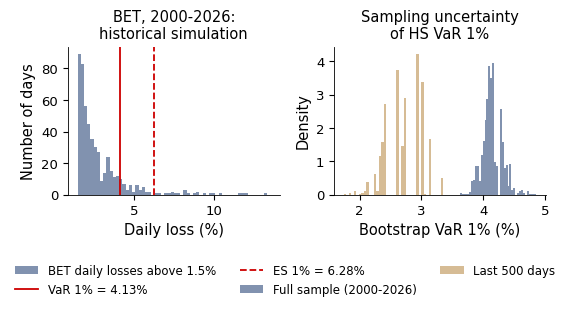

,full,w500
N,6670,500
start,2000-01-06,2024-09-12
var1,4.126959,2.711855
es1,6.278785,3.22082
var2_5,2.798908,2.054348
es2_5,4.569397,2.691839
ci_lo,3.847795,2.114385
ci_hi,4.456415,3.12267
n_beyond,67,5


In [ ]:
# Rezolvare
def b1_bet_hs():
    L = -100 * log_returns('bet')
    out = {}
    boots = {}
    for tag, x in [('full', L), ('w500', L.iloc[-500:])]:
        v1, e1 = hs_var_es(x, 0.01)
        v2, e2 = hs_var_es(x, 0.025)
        ci, bs = boot_ci(x.values, lambda y: hs_var_es(y, 0.01)[0])
        boots[tag] = bs
        out[tag] = dict(N=len(x), start=str(x.index[0].date()), var1=v1, es1=e1, var2_5=v2, es2_5=e2,
                        ci_lo=ci[0], ci_hi=ci[1], n_beyond=int((x >= v1).sum()))
    # chart: loss tail + bootstrap distributions
    _style()
    fig, axes = plt.subplots(1, 2, figsize=(W_FIG, 2.6))
    ax = axes[0]
    ax.hist(L[L > 1.5], bins=np.linspace(1.5, 13.5, 61), color=MainBlue, alpha=0.55, label='BET daily losses above 1.5%')
    ax.axvline(out['full']['var1'], color=IDAred, lw=1.3, label=f"VaR 1% = {out['full']['var1']:.2f}%")
    ax.axvline(out['full']['es1'], color=IDAred, ls='--', lw=1.3, label=f"ES 1% = {out['full']['es1']:.2f}%")
    ax.set_xlabel('Daily loss (%)')
    ax.set_ylabel('Number of days')
    ax.set_title('BET, 2000-2026:\nhistorical simulation')
    pass
    ax = axes[1]
    ax.hist(boots['full'], bins=40, density=True, color=MainBlue, alpha=0.55, label='Full sample (2000-2026)')
    ax.hist(boots['w500'], bins=40, density=True, color=Amber, alpha=0.55, label='Last 500 days')
    ax.set_xlabel('Bootstrap VaR 1% (%)')
    ax.set_ylabel('Density')
    ax.set_title('Sampling uncertainty\nof HS VaR 1%')
    bottom_legend(fig, ncol=3, fontsize=8.5)
    plt.tight_layout()
    save_fig('ch7_sem_bet_hs')
    return out


pd.DataFrame(b1_bet_hs()).round(3)

### B2. Precizia unei estimări ES [Propus]

- **Întrebare**: estimează un ES 2,5% istoric pe 500 de zile riscul din coadă cu o precizie de $\pm 0{,}3$ puncte procentuale (pp) [Pele & Mazurencu-Marinescu-Pele (2026)](https://doi.org/10.3390/math14132316)?

- **Date**

  - S&P 500 (închideri zilnice) și BET, pierderi log zilnice în %, 2000–2026; selecții: completă și ultimele 500 de zile

  - Folosiți funcția de reeșantionare din [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B1) (2 000 de reeșantionări, sămînța 42, blocuri de 20 de zile), cu ES 2,5% ca statistică

- **Cerințe**

  1.  Calculați ES 2,5%, numărul de observații din coadă $n\alpha$ și numărul $k$ de pierderi incluse efectiv în media din coadă.

  2.  Extrageți o reeșantionare i.i.d. și una pe blocuri pentru ultimele 500 de zile ale S&P 500 și recalculați pe fiecare VaR 2,5%, pierderile din coadă și ES.

  3.  Construiți intervalele de 95% i.i.d. și pe blocuri pentru toate cele patru selecții și comparați lățimile lor cu $0{,}6$ pp ($\pm 0{,}3$).

- **Raportați**: un tabel ($n\alpha$, $k$, ES, două intervale) și un grafic cu intervalele

- **Interpretare**

  - care selecții ating ținta de $\pm 0{,}3$ pp?

  - ce determină lățimea?

- **Repere și exemple**: [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B1)

[Exercițiul B2 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B2)

In [ ]:
# Codul vostru aici


### B3. VaR filtrat de mîine pentru Bitcoin [Propus]

- **Întrebare**: VaR 1% pentru Bitcoin pe 19 septembrie 2026: filtrat sau istoric?

- **Date**

  - Bitcoin (USD), închideri zilnice, 17 septembrie 2014 – 18 septembrie 2026, 7 zile pe săptămînă; randamente log zilnice în %

  - AR(1)-GARCH(1,1) prin cvasi-verosimilitate Normală (QML), cu intercept în AR: $r_t = \mu_t + \sigma_t z_t$ [Barone-Adesi et al. (1999)](https://doi.org/10.1002/(SICI)1096-9934(199908)19:5<583::AID-FUT5>3.0.CO;2-S)

- **Cerințe**

  1.  Estimați modelul pe întreaga selecție și prognozați $\hat\mu_{t+1}$, $\hat\sigma_{t+1}$.

  2.  Calculați $\hat\xi_{1\%} = -q_{1\%}(\hat z)$ din reziduurile standardizate și VaR 1% și ES 1% filtrate.

  3.  Comparați cu VaR și ES istorice pe ultimele 500 de zile și pe întreaga selecție.

  4.  Cu prognozele din cronologia de mai jos, numărați zilele de la 18 septembrie 2024 pînă la 18 septembrie 2026 cu pierdere peste VaR Filtered Historical Simulation (FHS) și peste un VaR Historical Simulation (HS) pe fereastră mobilă de 500 de zile.

- **Raportați**: trei perechi VaR/ES, două numere de depășiri și numărul așteptat $n\alpha$ sub calibrare pentru cele 731 de zile de evaluare

- **Repere și exemple**: [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B1) (cuantile istorice); [estimarea filtrului și prognoza pe o zi](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=sem7-filter-fit)

**Cronologia prognozelor (pasul 4)**

- În fiecare ianuarie: reestimăm GARCH folosind numai datele anterioare.
- În fiecare zi: prognozăm $\sigma_{t+1}$ din informația disponibilă pînă la $t$.
- Reziduurile folosite provin numai din perioada anterioară acelui ianuarie.

- Nicio prognoză nu folosește informație din ziua ei sau de mai tîrziu: un prag din întreaga selecție nu este o prognoză în afara eșantionului

- **Interpretare**

  - de ce diferă cele trei VaR?

  - care metodă greșește mai des?

[Exercițiul B3 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B3)

Pentru pasul 4 este furnizat fișierul `os.path.join(HERE, "ch7_rolling_btc.csv")`. Celula de pregătire îl produce; coloanele `loss`, `fhs_var` și `hs_var` conțin pierderea și cele două prognoze, în %. Cu `SAVE_TO_DRIVE=False`, `HERE` este folderul temporar. [FHS: prognoza pe o zi](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=sem7-filter-fit).

In [ ]:
# Codul vostru aici


### C1. Critica unui răspuns AI [Propus]

- **Cererea**: „`px` conține închiderile zilnice BET, 2000–2026. Dă-mi VaR 1% și ES 2,5% istorice pe o zi, ca pierderi log pozitive în %, și VaR 1% pe 10 zile.”

- **Răspunsul**: codul de mai jos, care rulează fără niciun mesaj de eroare

``` numberLines
import numpy as np
r = 100 * np.log(px).diff().dropna()                 # daily log returns, %
loss = -r                                            # log loss, %
var1 = np.percentile(r, 99)                          # VaR 1%
es25 = loss[loss >= np.percentile(loss, 99)].mean()  # ES 2.5%
var10 = 10 * var1                                    # 10-day VaR 1%
```

- **Concluzia AI**: „VaR 1% $= 3{,}95\%$, ES 2,5% $= 6{,}28\%$, VaR 1% pe 10 zile $= 39{,}46\%$.”

- **Întrebări**

  - ce linii din răspunsul AI sînt greșite?

  - care sînt cifrele corecte?

- **Date**: datele BET din [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B1); răspunsul conține **trei** greșeli tipice pentru VaR și ES, restul este corect

- **Cerințe**

  1.  Pentru fiecare greșeală, indicați numărul liniei și explicați într-o frază de ce este greșită, folosind $\operatorname{VaR}_\alpha = -q_\alpha(r) = q_{1-\alpha}(L)$.

  2.  Precizați cum ați depista-o: o numărătoare a observațiilor, o cifră din [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B1) sau un slide din curs.

  3.  Scrieți liniile corectate, inclusiv VaR pe 10 zile din pierderile suprapuse pe 10 zile, și recalculați cele trei cifre.

  4.  Verificați ES 2,5% corectat: pe cîte pierderi se calculează media? Pe cîte ar trebui calculată?

- **Raportați**: un tabel al erorilor (linia, eroarea, depistarea, corecția) și cifrele corectate; notați fiecare eroare găsită efectiv în `AI_ERRORS.md`

- **Interpretare**: de ce rulează codul fără mesaj de eroare, deși răspunsul este greșit?

- **Repere și exemple**: [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B1)

[Exercițiul C1 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-C1)

In [ ]:
# C1: codul dumneavoastră corectat


### B4. O coadă GPD pentru BET [Rezolvat] — după curs

- **Întrebare**: ce aduce în plus un model de valori extreme pentru coadă față de simularea istorică, în extremitatea cozii?

- **Date**

  - Pierderile BET din [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B1) ($n = 6\,670$)

  - Depășiri de prag [McNeil, Frey & Embrechts (2015)](https://press.princeton.edu/books/hardcover/9780691166278/quantitative-risk-management): GPD cu forma $\xi$ și scala $\beta$, erorile ei standard și VaR și ES pentru coadă (formulele: [„Depășiri de prag: distribuția GPD”](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=sem7p15)); $N_u$ = numărul de depășiri

- **Cerințe**

  1.  Fixați $u$ = cuantila empirică de 95% a lui $L$ și formați excesele $L - u$ ale pierderilor de peste el.

  2.  Estimați GPD prin verosimilitate maximă cu locația fixată la 0: `scipy.stats.genpareto.fit(excese, floc=0)`.

  3.  Calculați erorile standard i.i.d. $\mathrm{SE}(\hat\xi)$ și $\mathrm{SE}(\hat\beta)$.

  4.  Calculați VaR și ES GPD la $1\%$, $0{,}5\%$ și $0{,}1\%$ și comparați cu simularea istorică.

  5.  Re-estimați pentru praguri depășite de 10% pînă la 1,5% dintre pierderi și reprezentați $\hat\xi$ cu benzi de 95%.

- **Raportați**: estimarea cu erorile standard, un tabel VaR/ES cu șase rînduri și numărul de observații din coadă, graficul de stabilitate

- **Interpretare**

  - este coada BET mai grea decît distribuția Normală?

  - cît de precisă este această concluzie?

- **1–2.** $u = 1{,}93\%$ lasă deasupra $N_u = 334$ din $n = 6\,670$ pierderi; $\hat\xi = 0{,}209$, $\hat\beta = 1{,}20$

- **3.** $\mathrm{SE}(\hat\xi) = (1 + 0{,}209)/\sqrt{334} = 0{,}066$, $\mathrm{SE}(\hat\beta) = 0{,}10$; $\hat\xi/\mathrm{SE} = 3{,}2$

- **4.** VaR 1%: $N_u/n = 0{,}050$, $(0{,}01/0{,}050)^{-0{,}209} = 1{,}401$

  - $\operatorname{VaR}_{1\%} = 1{,}93 + \frac{1{,}20}{0{,}209}(1{,}401 - 1) = 4{,}22\%$



|  | $\operatorname{VaR}$ GPD | $\operatorname{VaR}$ ist. | $\operatorname{ES}$ GPD | $\operatorname{ES}$ ist. |
|:---|---:|---:|---:|---:|
| 1% | $4{,}22$ | $4{,}13$ | $6{,}34$ | $6{,}28$ |
| 0,5% | $5{,}47$ | $5{,}38$ | $7{,}92$ | $7{,}86$ |
| 0,1% | $9{,}18$ | $9{,}50$ | $12{,}61$ | $11{,}25$ |



- Pierderi dincolo de VaR istoric: 67 la 1%, 34 la 0,5%, 7 la 0,1%

- Cele două metode coincid pînă la 0,5%; la 0,1% ES istoric este media a 7 numere, în timp ce GPD folosește toate cele 334 de excese printr-o coadă estimată

- Stînga: GPD urmează coada empirică, coada Normală cade mult sub ea; dreapta: $\hat\xi$ variază între $0{,}15$ și $0{,}30$ pe praguri, iar VaR 0,1% doar între $9{,}04\%$ și $9{,}51\%$

- Interpretare: coada este mai grea decît cea Normală, dar Standard Error (SE) i.i.d. presupune depășiri independente; pierderile BET sînt grupate, deci incertitudinea reală este mai mare ([B4](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B4) extins: indicele extremal)

[Exercițiul B4 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B4)

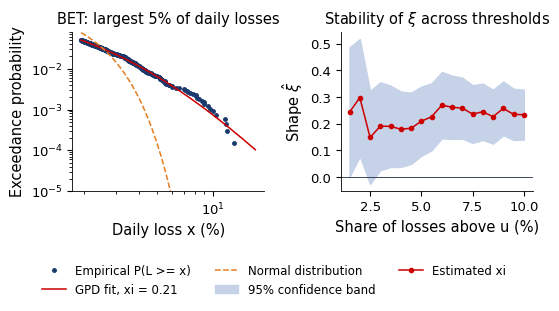

{'u': np.float64(1.9341864302995664),
 'xi': np.float64(0.20917979223399713),
 'beta': np.float64(1.1958177470341624),
 'nu': 334,
 'n': 6670,
 'se_xi': np.float64(0.06616337450274115),
 'se_beta': np.float64(0.10175416603506886),
 'evt_var1': np.float64(4.224892668482573),
 'evt_es1': np.float64(6.342930606256186),
 'hs_var1': np.float64(4.126958579751895),
 'hs_es1': np.float64(6.278784853593418),
 'n_beyond1': 67,
 'evt_var0_5': np.float64(5.474294112578411),
 'evt_es0_5': np.float64(7.922811130080035),
 'hs_var0_5': np.float64(5.378918259997512),
 'hs_es0_5': np.float64(7.855143286665594),
 'n_beyond0_5': 34,
 'evt_var0_1': np.float64(9.179474502863357),
 'evt_es0_1': np.float64(12.608048499964339),
 'hs_var0_1': np.float64(9.501589895769133),
 'hs_es0_1': np.float64(11.251818425971067),
 'n_beyond0_1': 7,
 'xi_range': [0.14851096707479988, 0.2976438909186965],
 'v0_1_range': [9.041439776125427, 9.51187997520639]}

In [ ]:
# Rezolvare
def b4_bet_gpd():
    L = (-100 * log_returns('bet')).values
    f = gpd_fit(L, 0.05)
    se_xi, se_beta = gpd_se(f)
    out = dict(u=f['u'], xi=f['xi'], beta=f['beta'], nu=f['nu'], n=f['n'], se_xi=se_xi, se_beta=se_beta)
    for a, tag in [(0.01, '1'), (0.005, '0_5'), (0.001, '0_1')]:
        v, e = gpd_var_es(f, a)
        hv, he = hs_var_es(L, a)
        out.update({f'evt_var{tag}': v, f'evt_es{tag}': e, f'hs_var{tag}': hv, f'hs_es{tag}': he,
                    f'n_beyond{tag}': int((L >= hv).sum())})
    # sensitivity to the threshold
    qs = np.linspace(0.10, 0.015, 18)          # share of losses above the threshold
    xis, lo, hi, v01 = [], [], [], []
    for q in qs:
        g = gpd_fit(L, q)
        s = gpd_se(g)[0]
        xis.append(g['xi'])
        lo.append(g['xi'] - 1.96 * s)
        hi.append(g['xi'] + 1.96 * s)
        v01.append(gpd_var_es(g, 0.001)[0])
    out['xi_range'] = [float(min(xis)), float(max(xis))]
    out['v0_1_range'] = [float(min(v01)), float(max(v01))]
    _style()
    fig, axes = plt.subplots(1, 2, figsize=(W_FIG, 2.6))
    ax = axes[0]
    xs = np.sort(L[L > f['u']])
    emp = (1 - np.arange(len(xs)) / len(xs)) * f['nu'] / f['n']
    ax.loglog(xs, emp, 'o', ms=2.5, color=MainBlue, label='Empirical P(L >= x)')
    xx = np.linspace(f['u'], xs[-1] * 1.3, 200)
    ax.loglog(xx, f['nu'] / f['n'] * stats.genpareto.sf(xx - f['u'], f['xi'], scale=f['beta']), color=IDAred,
              label=f"GPD fit, xi = {f['xi']:.2f}")
    ax.loglog(xx, stats.norm.sf(xx, L.mean(), L.std()), color=Orange, ls='--', label='Normal distribution')
    ax.set_ylim(1e-5, 0.08)
    ax.set_xlabel('Daily loss x (%)')
    ax.set_ylabel('Exceedance probability')
    ax.set_title('BET: largest 5% of daily losses')
    pass
    ax = axes[1]
    ax.fill_between(100 * qs, lo, hi, color=LightGray, label='95% confidence band')
    ax.plot(100 * qs, xis, 'o-', ms=3, color=IDAred, label='Estimated xi')
    ax.axhline(0, color=Gray, lw=0.6)
    ax.set_xlabel('Share of losses above u (%)')
    ax.set_ylabel(r'Shape $\hat\xi$')
    ax.set_title(r'Stability of $\xi$ across thresholds')
    bottom_legend(fig, ncol=3, fontsize=8.5)
    plt.tight_layout()
    save_fig('ch7_sem_bet_gpd')
    return out


b4_bet_gpd()

### A5. Contribuțiile la risc a două active [Rezolvat] — după curs

- **Întrebare**: contribuie fiecare activ la risc proporțional cu capitalul investit în el?

- **Date**

  - Expuneri monetare $w = (600\,000,\ 400\,000)$ EUR în acțiuni și obligațiuni; randamente simple zilnice $R$ în zecimale, abateri standard $\sigma_1 = 0{,}012$, $\sigma_2 = 0{,}009$, corelația $\rho = -0{,}2$

  - $\Sigma = \begin{pmatrix} 0{,}000144 & -0{,}0000216 \\ -0{,}0000216 & 0{,}000081 \end{pmatrix}$; ($\Sigma$: matricea de covarianță) randamente cu distribuție Normală comună, media neglijată, $\alpha = 1\%$, $z_{99\%} = 2{,}326$ (cuantila de 99% a distribuției Normale standard)

- **Cerințe**

  1.  Calculați abaterea standard a portofoliului $\sigma_p$ în EUR și VaR 1% al portofoliului (formulele: [„Contribuțiile la risc (alocarea Euler)”](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=sem7p18)).

  2.  Calculați $\Sigma w$, VaR marginal pe EUR și VaR pe componente $C_i$; verificați $C_1 + C_2 = \operatorname{VaR}$ [Tasche (2008)](https://arxiv.org/abs/0708.2542).

  3.  Calculați beneficiul diversificării: suma VaR-urilor individuale minus VaR-ul portofoliului.

  4.  Sub distribuția Normală, rescalați fiecare $C_i$ cu $\dfrac{\varphi(z_{1\%})/0{,}01}{z_{99\%}}$ pentru a obține contribuțiile la ES 1%.

- **Raportați**: un tabel cu $C_i$, $C_i^{ES}$ și cotele lor și beneficiul diversificării în EUR

- **Interpretare**: contribuie obligațiunile la risc proporțional cu ponderea lor de 40% din capital?

- **1.** $\sigma_p^2 = 7\,200^2 + 3\,600^2 + 2(-0{,}2)(7\,200)(3\,600) = 54\,432\,000$, $\sigma_p = 7\,378$ EUR, $\operatorname{VaR}_{1\%} = 2{,}326 \cdot 7\,378 = 17\,163$ EUR

- **2.** $\Sigma w = (77{,}76; 19{,}44)$; VaR marginal pe EUR $(0{,}0245; 0{,}0061)$; $C_1 = 14\,711$ ($85{,}7\%$), $C_2 = 2\,452$ ($14{,}3\%$), suma $17\,163$ EUR

- **3.** Individual $16\,750 + 8\,375 = 25\,125$ EUR față de $17\,163$ EUR

- **4.** Factorul $1{,}146$: $C_1^{ES} = 16\,854$, $C_2^{ES} = 2\,809$, total $19\,663$ EUR = ES 1%; aceleași cote ca VaR sub distribuția Normală



- Interpretare: obligațiunile au 40% din capital, dar $14{,}3\%$ din risc: corelația negativă le transformă într-o acoperire parțială (hedge)

[Exercițiul A5 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A5)

In [ ]:
# Rezolvare
def a5_components(pos=(600_000, 400_000), sig=(1.2, 0.9), rho=-0.2, alpha=0.01):
    """Component VaR 1% for two assets, Normal distribution, zero mean."""
    w = np.array(pos, float)
    s = np.array(sig) / 100
    S = np.array([[s[0] ** 2, rho * s[0] * s[1]], [rho * s[0] * s[1], s[1] ** 2]])
    sp = np.sqrt(w @ S @ w)
    z = stats.norm.ppf(1 - alpha)              # z_{1-alpha} = -z_alpha > 0
    Sw = S @ w
    mvar = z * Sw / sp
    cvar = w * mvar
    return dict(w=w, s=s, rho=rho, z=z, var_p_amt=z * sp, sigma_p_amt=sp, sp2=sp ** 2, Sw=Sw, mvar=mvar, cvar=cvar,
                share=cvar / (z * sp), var_ind=z * s * w, undiv=(z * s * w).sum())


a5_components()

{'w': array([600000., 400000.]),
 's': array([0.012, 0.009]),
 'rho': -0.2,
 'z': np.float64(2.3263478740408408),
 'var_p_amt': np.float64(17163.33993344972),
 'sigma_p_amt': np.float64(7377.804551490911),
 'sp2': np.float64(54432000.0),
 'Sw': array([77.76, 19.44]),
 'mvar': array([0.02451906, 0.00612976]),
 'cvar': array([14711.43422867,  2451.90570478]),
 'share': array([0.85714286, 0.14285714]),
 'var_ind': array([16749.70469309,  8374.85234655]),
 'undiv': np.float64(25124.557039641084)}

In [ ]:
# Rezolvare
a5 = a5_components()
k = stats.norm.pdf(stats.norm.ppf(0.01)) / 0.01 / stats.norm.ppf(0.99)
{'ratio': k, 'C_ES': [c * k for c in a5['cvar']], 'ES_p': a5['var_p_amt'] * k}

{'ratio': np.float64(1.1456645199483257),
 'C_ES': [np.float64(16854.36823334195), np.float64(2809.0613722236585)],
 'ES_p': np.float64(19663.4296055656)}

### B5. Contribuțiile la risc într-un portofoliu cu patru active [Propus] — după curs

- **Întrebare**: într-un portofoliu cu ponderi egale în SPY, TLT, GLD și Bitcoin, ce active generează riscul?

- **Date**

  - SPY, TLT, GLD (închideri ajustate) și Bitcoin (închideri în USD), 18 septembrie 2014 – 18 septembrie 2026; aliniați mai întîi prețurile, apoi păstrați 3 017 randamente simple zilnice comune $R$ în %

  - Ponderi fracționare $w_i = 25\%$, rebalansare zilnică; $\Sigma$ = covarianța de selecție a lui $R$ (în %$^2$); VaR 1% Normal cu media neglijată; ES 2,5% istoric

- **Cerințe**

  1.  Calculați VaR 1% Normal, VaR marginal și VaR pe componente pentru fiecare activ, ca în [A5](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A5).

  2.  Calculați ES 2,5% istoric al pierderii portofoliului $L_p = -w^\top R$ și contribuțiile $\mathbb{E}[-w_iR_i \mid L_p \ge \operatorname{VaR}_{2{,}5\%}]$ ca medii pe zilele din coadă.

  3.  Calculați VaR nediversificat $\sum_i z_{99\%}w_i\sigma_i$.

- **Raportați**: un tabel cu ponderi, contribuții și cote și un grafic al ponderilor în capital față de cotele de risc

- **Interpretare**: implică ponderi egale în capital contribuții egale la risc? (compararea VaR 1% Normal cu ES 2,5% istoric schimbă atît modelul, cît și nivelul)

- **Repere și exemple**: [A5](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A5)

[Exercițiul B5 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B5)

In [ ]:
# Codul vostru aici


### A2 extins. Integrala cozii Student-t [Rezolvat]

- **Întrebare**: cum se obține factorul ES Student-$t$ din [A2](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A2)?

- **Date**: $g_\nu(x) = c_\nu(1 + x^2/\nu)^{-(\nu + 1)/2}$, densitatea $t_\nu$; $c_\nu$: constanta care face ca integrala ei să fie 1

- **Cerințe**

  1.  Derivați $(1 + x^2/\nu)^{-(\nu - 1)/2}$.

  2.  Deduceți $\int_{-\infty}^{t} x g_\nu(x)\,dx = -g_\nu(t)\frac{\nu + t^2}{\nu - 1}$ și precizați unde este nevoie de $\nu > 1$.

- **Raportați**: demonstrația în două rînduri



Rezolvare

- **1.** $\frac{d}{dx}(1 + x^2/\nu)^{-(\nu - 1)/2} = -\frac{\nu - 1}{\nu}\,x\,(1 + x^2/\nu)^{-(\nu + 1)/2}$, deci $x g_\nu(x) = -\frac{\nu c_\nu}{\nu - 1}\frac{d}{dx}(1 + x^2/\nu)^{-(\nu - 1)/2}$

- **2.** Integrînd de la $-\infty$ la $t$: $-\frac{\nu}{\nu - 1}g_\nu(t)(1 + t^2/\nu) = -g_\nu(t)\frac{\nu + t^2}{\nu - 1}$; termenul de la $-\infty$ se anulează doar dacă $\nu > 1$

- ES cere $\nu > 1$; pentru o dispersie finită este necesar $\nu > 2$



[Exercițiul A2 extins din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A2)

### A4 extins. La ce niveluri nu este VaR subaditiv? [Propus]

- **Întrebare**: pentru ce probabilități ale cozii $\alpha$ nu este VaR subaditiv în [A4](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A4)?

- **Date**: obligațiunile din [A4](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A4), $p = 0{,}7\%$, și definiția VaR din secțiunea [„VaR și ES”](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=sem7p1)

- **Cerințe**

  1.  Scrieți $\operatorname{VaR}_\alpha(A)$ și $\operatorname{VaR}_\alpha(A + B)$ ca funcții în trepte de $\alpha$.

  2.  Găsiți intervalul lui $\alpha$ în care $\operatorname{VaR}_\alpha(A + B) > 2\operatorname{VaR}_\alpha(A)$ și explicați ambele capete.

- **Raportați**: intervalul și cîte o frază pentru fiecare capăt

- **Repere și exemple**: [A4](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A4)

[Exercițiul A4 extins din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A4)

In [ ]:
# Codul vostru aici


### A6. Validitatea transformării Cornish–Fisher ca funcție cuantilă [Propus]

- **Întrebare**: pentru ce exces de kurtosis mai este transformarea Cornish–Fisher o funcție cuantilă?

- **Date**

  - $\mu = 0$, $\sigma = 1{,}2\%$, asimetria $S = -0{,}5$, excesul de kurtosis $K$ [Cornish & Fisher (1938)](https://doi.org/10.2307/1400905)

  - Transformarea Cornish–Fisher $\tilde z(z)$ din secțiunea [„Dezvoltarea Cornish–Fisher (CF)”](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=sem7p19); $\operatorname{VaR}_\alpha = -\sigma\tilde z(z_\alpha)$

- **Cerințe**

  1.  Cu $K = 3$, calculați cei trei termeni de corecție în $z_{1\%}$, $\tilde z_{1\%}$ și VaR 1% Cornish–Fisher.

  2.  Scrieți $d\tilde z/dz = Az^2 + Bz + C$ și găsiți vîrful acestei parabole.

  3.  Găsiți cel mai mare $K$ pentru care $\tilde z$ este crescătoare pe $[z_{0{,}1\%}, 0]$ și decideți dacă $K = 10$ este admisibil.

- **Raportați**: VaR, limita pentru $K$ și un grafic al lui $\tilde z$ și $d\tilde z/dz$ pentru $K = 3$ și $K = 10$

- **Interpretare**: garantează o transformare cuantilă validă și un VaR precis?

- **Repere și exemple**: [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A1)

[Exercițiul A6 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A6)

In [ ]:
# Codul vostru aici


### A7. ES ca minim și subaditivitatea [Propus]

- **Întrebare**: de ce nu poate ES recompensa niciodată divizarea unui portofoliu?

- **Date**

  - Pierdere integrabilă $L$; funcția obiectiv $G_\alpha(v)$ [Rockafellar & Uryasev (2000)](https://doi.org/10.21314/jor.2000.038) din secțiunea [„ES ca minim”](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=sem7p6)

  - Cifre: portofoliul din [A4](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A4) (două obligațiuni, $p = 0{,}7\%$) la $\alpha = 1\%$

- **Cerințe**

  1.  Pentru portofoliul din [A4](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A4), calculați pantele lui $G$ pe $(0, 100)$ și $(100, 200)$, punctul de minim și minimul.

  2.  Arătați că derivata la dreapta a lui $G$ este $1 - P(L > v)/\alpha$ și deduceți că $\operatorname{VaR}_\alpha$ minimizează $G$, cu minimul $\operatorname{ES}_\alpha$.

  3.  Deduceți $\operatorname{ES}_\alpha(L_1 + L_2) \le \operatorname{ES}_\alpha(L_1) + \operatorname{ES}_\alpha(L_2)$ din $(a + b)_+ \le a_+ + b_+$.

- **Raportați**: cele trei cifre de la pasul 1 și două demonstrații scurte

- **Repere și exemple**: [A3](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A3), [A4](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A4)

[Exercițiul A7 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A7)

In [ ]:
# Codul vostru aici


### A5 extins. Contribuțiile la ES din minim [Rezolvat]

- **Întrebare**: de ce sînt contribuțiile istorice la ES din [B5](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B5) medii pe zilele din coadă?

- **Date**: $\operatorname{ES}_\alpha(w) = \min_v G(w, v)$, $G(w, v) = v + \mathbb{E}[(L_p - v)_+]/\alpha$, $L_p = -w^\top R$ ([A7](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A7))

- **Cerințe**

  1.  Folosiți argumentul înfășurătoarei în $v^* = \operatorname{VaR}_\alpha$ pentru a calcula $\partial\operatorname{ES}_\alpha/\partial w_i$.

  2.  Arătați că $w_i\,\partial\operatorname{ES}_\alpha/\partial w_i = \mathbb{E}[-w_iR_i \mid L_p \ge \operatorname{VaR}_\alpha]$ pentru $L_p$ continuu.

- **Raportați**: o demonstrație scurtă

- **Repere și exemple**: [A7](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A7)



Rezolvare

- $\partial G/\partial v = 0$ în $v^*$, deci $\partial\operatorname{ES}_\alpha/\partial w_i = \partial G/\partial w_i(w, v^*) = \mathbb{E}[-R_i\mathbf{1}\{L_p > v^*\}]/\alpha$

- Pentru $L_p$ continuu, $P(L_p > v^*) = \alpha$: aceasta este $\mathbb{E}[-R_i \mid L_p \ge \operatorname{VaR}_\alpha]$; suma lui $w_i\times$ ea dă $\operatorname{ES}_\alpha$ (Euler)

- Estimarea istorică: media lui $-w_iR_i$ pe zilele din coadă ([B5](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B5)); sub distribuția Normală este egală cu rescalarea VaR din [A5](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A5)



[Exercițiul A5 extins din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A5)

### A8. Dispersia de selecție a ES istoric [Propus]

- **Întrebare**: cît de imprecis este un ES 2,5% istoric pe 500 de zile, chiar pentru pierderi Normale?

- **Date**

  - $n$ pierderi i.i.d., continue, densitate pozitivă în $\operatorname{VaR}_\alpha$, $\mathbb{E}[L^2] < \infty$; $Y = (L - \operatorname{VaR}_\alpha)_+$, excesul pierderii peste VaR (0 sub el)

  - Funcția de influență $\mathrm{IF}$ [Chen (2008)](https://doi.org/10.1093/jjfinec/nbm019) și $\operatorname{Var}(\widehat{\operatorname{ES}}_\alpha) \approx \operatorname{Var}(\mathrm{IF}(L))/n$ din secțiunea [„Precizia ES”](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=sem7p11)

- **Cerințe**

  1.  Arătați că $\operatorname{Var}(\mathrm{IF}(L)) = \operatorname{Var}(Y)/\alpha^2$ și explicați, cu [A7](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A7), de ce estimarea VaR nu adaugă niciun termen de ordinul întîi.

  2.  Pentru $L \sim N(0, 1)$, $\alpha = 2{,}5\%$, integrați, cu $v = \operatorname{VaR}_\alpha = -z_\alpha$, $\mathbb{E}[Y] = \int_v^\infty (x - v)\varphi(x)\,dx$ și $\mathbb{E}[Y^2]$ în formă închisă.

  3.  Calculați SE a lui $\widehat{\operatorname{ES}}_{2{,}5\%}$ pentru $n = 500$ și $\sigma = 1{,}2\%$ și verificați-o cu 4 000 de selecții independente (NumPy default_rng(42)); folosiți interpolarea liniară a cuantilei, media pierderilor cel puțin egale cu ea și ddof=1 pentru abaterea standard simulată.

- **Raportați**: cele două momente, SE în pp și abaterea standard simulată

- **Interpretare**: de ce este valoarea pentru S&P 500 ([B2](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B2)) mult mai mare?

- **Repere și exemple**: [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A1), [A7](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A7)

[Exercițiul A8 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A8)

In [ ]:
# Codul vostru aici


### B1 extins. Intervale asimptotice și HAC pentru VaR [Rezolvat]

- **Întrebare**: coincid formulele asimptotice cu bootstrap-ul din [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B1)?

- **Date**

  - Pierderile BET din [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B1); erorile standard i.i.d. și HAC din secțiunea [„Precizia VaR”](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=sem7p10) (densitatea nucleu $\hat f$, lagul Newey–West $\lfloor 4(n/100)^{2/9}\rfloor$)

- **Cerințe**

  1.  Reperul Normal (din [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A1)): cu $f(\operatorname{VaR}_{1\%}) = \varphi(z_{1\%})/1{,}2$, calculați SE pentru $n = 500$ și $n = 6\,670$.

  2.  Pentru BET, calculați $\hat f$, SE i.i.d. și HAC și cele două intervale de 95% pe ambele selecții.

- **Raportați**: cele patru intervale pentru VaR 1% lîngă cele două intervale bootstrap din [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B1)

- **Interpretare**: de ce sînt intervalele BET mai largi decît reperul Normal?

- **1.** $f = 0{,}0267/1{,}2 = 0{,}0222$: SE $0{,}20$ pp ($n = 500$, lățime $0{,}79$), $0{,}055$ pp ($n = 6\,670$, lățime $0{,}22$)

- **2.** BET complet: $\hat f = 0{,}0076$, SE $0{,}16$ (i.i.d.), $0{,}23$ (HAC); intervale $[3{,}81; 4{,}44]$, $[3{,}69; 4{,}57]$

- Ultimele 500 de zile: $\hat f = 0{,}0163$, SE $0{,}27$ și $0{,}27$

- Interpretare: coada BET este mai grea decît cea Normală, deci densitatea în VaR este mai mică și cuantila mai puțin precisă; HAC și blocurile confirmă că volatility clustering lărgește intervalul pe întreaga selecție

- Graficul celor patru intervale pentru fiecare selecție: [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B1), rezolvare — intervale

[Exercițiul B1 extins din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B1)

In [ ]:
print(SX['a1'])

{'f': np.float64(0.022210118502881734), 'se500': np.float64(0.2003464813427291), 'se6670': np.float64(0.0548534319298592)}


In [ ]:
# intervalul bootstrap pe blocuri din B1 și intervalele asimptotice (i.i.d., HAC) din B1 extins pentru VaR 1%
pd.DataFrame({'full': SX['b1_full'], 'last 500': SX['b1_w500']}).round(3)

,full,last 500
var1,4.127,2.712
f,0.008,0.016
se,0.160,0.273
se_hac,0.225,0.266
lo,3.813,2.177
hi,4.441,3.246
lo_hac,3.686,2.190
hi_hac,4.568,3.234
blk_lo,3.609,2.023
blk_hi,4.801,3.032


În prima ieșire, `f` este densitatea Normală la VaR; `se500` și `se6670` sînt erorile standard pentru cele două mărimi de eșantion. În tabelul BET, `f` este densitatea estimată, `se` eroarea standard i.i.d., `se_hac` cea HAC; `lo`/`hi` și `lo_hac`/`hi_hac` delimitează intervalele asimptotice. `blk_lo`/`blk_hi` sînt limitele bootstrap cu blocuri. Toate limitele VaR sînt în procente de pierdere, iar erorile standard în puncte procentuale.

### B3 extins. Un interval bootstrap pentru FHS VaR de mîine [Propus]

- **Întrebare**: cît de incert este VaR filtrat din [B3](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B3)?

- **Date**: modelul și datele din [B3](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B3); bootstrap pe reziduuri [Christoffersen & Gonçalves (2005)](https://doi.org/10.21314/jor.2005.112) cu 999 de traiectorii, sămînța 42, funcția `fhs_bootstrap` din Quantlet-ul seminarului

- **Cerințe**

  1.  Pentru fiecare traiectorie, simulați o serie AR(1)-GARCH(1,1) de lungimea selecției cu $\hat z$ reeșantionate și re-estimați $\theta^* = (c^*, \phi^*, \omega^*, \alpha_1^*, \beta_1^*)$.

  2.  Calculați $\mu^*_{t+1}$ și $\sigma^*_{t+1}$ trecînd randamentele Bitcoin **originale** prin $\theta^*$ și $\hat\xi^*_{1\%}$ din reziduurile traiectoriei.

  3.  Raportați intervalul percentil de 90% al lui $\operatorname{VaR}^* = -\mu^*_{t+1} + \sigma^*_{t+1}\hat\xi^*_{1\%}$ și intervalele celor două surse.

- **Raportați**: histograma celor 999 de prognoze cu intervalul

- **Interpretare**

  - include intervalul VaR istoric pe 500 de zile?

  - este aceasta un test?

- **Repere și exemple**: [B3](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B3)

[Exercițiul B3 extins din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B3)

In [ ]:
# Codul vostru aici


### B6. Cornish–Fisher față de cuantilele empirice [Propus]

- **Întrebare**: corectează dezvoltarea Cornish–Fisher VaR Normal pe date reale?

- **Date**

  - BET (obligatoriu): datele din [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B1); extindere: S&P 500, Bitcoin și aur (închideri zilnice, zile lucrătoare pentru aur) și cursul de referință BNR EUR/RON (2005–2026), toate pînă la 18 septembrie 2026

  - Momentele randamentelor $X$: media, abaterea standard cu `ddof=1`, `scipy.stats.skew` și `scipy.stats.kurtosis` (exces, deplasat)

- **Cerințe**

  1.  Calculați $S$ și $K$ pentru BET.

  2.  Calculați VaR 1% și VaR 2,5% prin distribuția Normală, Cornish–Fisher ([A6](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A6)) și simularea istorică.

  3.  Construiți intervale bootstrap i.i.d. de 95% (1 000 de reeșantionări) pentru cele două VaR istorice și verificați dacă valorile Cornish–Fisher cad în interior.

  4.  Separat, verificați dacă $K$ depășește limita de monotonie din [A6](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A6).

- **Raportați**: un tabel mic pe activ și un grafic cu cele trei metode și intervalele bootstrap

- **Interpretare**: la ce nivel al cozii se apropie Cornish–Fisher mai mult de reperul istoric? Se păstrează concluzia pentru fiecare activ?

- **Repere și exemple**: [A1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A1), [A6](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-A6), [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B1)

[Exercițiul B6 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B6)

In [ ]:
# Codul vostru aici


### B5 extins. Ponderi risk parity [Propus]

- **Întrebare**: ce ponderi nenegative, cu investiție integrală, dau fiecărui activ din [B5](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B5) aceeași cotă din VaR Normal?

- **Date**: randamentele și covarianța $\Sigma$ din [B5](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B5)

- **Cerințe**

  1.  Rezolvați numeric $w_i(\Sigma w)_i = w_j(\Sigma w)_j$ pentru toți $i, j$, cu $w \ge 0$ și $\sum_i w_i = 1$.

  2.  Comparați cu ponderile invers proporționale cu volatilitatea, $w_i \propto 1/\sigma_i$.

  3.  La ponderile de paritate a riscului, calculați VaR 1% Normal, ES 2,5% istoric și cotele ES.

- **Raportați**: ponderile, VaR, ES și cotele

- **Interpretare**: implică cotele egale din VaR cote egale din ES?

- **Repere și exemple**: [B5](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B5)

[Exercițiul B5 extins din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B5)

In [ ]:
# Codul vostru aici


### B4 extins. Depășiri grupate și indicele extremal [Rezolvat]

- **Întrebare**: cîte informații independente despre coadă conțin cele 334 de depășiri BET din [B4](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B4)?

- **Date**

  - Momentele de depășire $S_1 < \dots < S_N$ ale lui $u$ ([B4](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B4)), intervalele $T_i = S_{i+1} - S_i$

  - Estimatorul pe intervale $\hat\theta$ [Ferro & Segers (2003)](https://doi.org/10.1111/1467-9868.00401) din secțiunea [„Depășiri grupate: indicele extremal”](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=sem7p17)

- **Cerințe**

  1.  Calculați $\hat\theta$ cu precizia completă (rotunjiți doar valoarea afișată) și numărul țintă de grupuri $C = \lfloor\hat\theta N\rfloor + 1$.

  2.  Împărțiți depășirile la cele mai mari $C - 1$ intervale; dacă al $(C - 1)$-lea și al $C$-lea cel mai mare interval sînt egale, reduceți $C$ pînă cînd diferă.

  3.  Estimați GPD pe maximele grupurilor și comparați $\hat\xi/\mathrm{SE}$ cu [B4](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B4).

- **Raportați**: $\hat\theta$, numărul de grupuri, estimarea pe maximele grupurilor și un grafic cronologic

- **Interpretare**: este credibilă SE i.i.d. din [B4](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B4)?

- **1.** $\hat\theta = 0{,}32$, $C = 108$

- **2.** Egalitate la pragul de separare ($T = 12$ zile): 100 de grupuri de cîte 3,3 depășiri în medie; cel mai mare grup 33, 47 depășiri izolate

- **3.** $\hat\xi = 0{,}269$ (SE $0{,}127$) față de $0{,}209$ (SE $0{,}066$); $\hat\xi/\mathrm{SE}$ scade de la $3{,}2$ la $2{,}1$; la pragul VaR 1% $\hat\theta = 0{,}40$

- Interpretare: coada rămîne grea, dar SE i.i.d. nu este credibilă; raportăm estimarea pe maximele grupurilor sau filtrăm întîi cu GARCH (EVT condiționată)

[Exercițiul B4 extins din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B4)

In [ ]:
# B4 extins: indicele extremal și GPD pe maximele grupurilor
print(extremal_index(loss['bet'].values, 0.05))
extremal_index(loss['bet'].values, 0.01)

{'u': np.float64(1.9341864302995664), 'N': 334, 'theta': np.float64(0.32078876105010007), 'n_clusters': 100, 'mean_size': 3.34, 'xi': np.float64(0.20917979223399713), 'se_xi': np.float64(0.06616337450274115), 'xi_c': np.float64(0.268679519873381), 'se_xi_c': np.float64(0.12686795198733808), 'beta_c': np.float64(1.4742231495306608), 'se_xi_eff': np.float64(0.11681754503612903)}


{'u': np.float64(4.126958579751895),
 'N': 67,
 'theta': np.float64(0.39791070574334986),
 'n_clusters': 27,
 'mean_size': 2.4814814814814814,
 'xi': np.float64(0.07321034769304616),
 'se_xi': np.float64(0.13111351185509657),
 'xi_c': np.float64(-0.34430900963060845),
 'se_xi_c': np.float64(0.12618778993166016),
 'beta_c': np.float64(4.181159464672045),
 'se_xi_eff': np.float64(0.20785220595817536)}

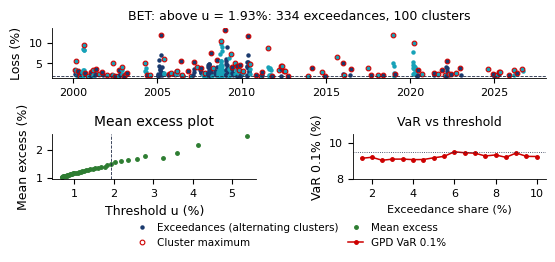

{'u': np.float64(1.9341864302995664), 'N': 334, 'n_clusters': 100, 'theta': np.float64(0.32078876105010007), 'cut': 12.0, 'max_size': 33, 'n_single': 47, 'hs_var01': 9.501589895769133}
{'C_before_ties': 108}


In [ ]:
def clusters_bet(L, tail=0.05):
    """Threshold exceedances, clusters (Ferro & Segers, 2003, tie rule) and cluster maxima."""
    L = np.asarray(L, float)
    u = np.quantile(L, 1 - tail)
    S = np.flatnonzero(L > u)
    T = np.diff(S).astype(float)
    N = len(S)
    th = min(1.0, 2 * (T - 1).sum() ** 2 / ((N - 1) * ((T - 1) * (T - 2)).sum()))
    C = min(int(np.floor(th * N)) + 1, N)
    cut = np.sort(T)[::-1][C - 2]
    breaks = np.flatnonzero(T > cut) if np.sum(T >= cut) > C - 1 else np.flatnonzero(T >= cut)
    groups = np.split(np.arange(N), breaks + 1)
    return u, S, groups, th, cut

def fig_b4_ext():
    """B4 Extended: timeline of exceedances and clusters, mean excess, stability of VaR 0.1% across thresholds."""
    _style()
    Ls = -100 * log_returns('bet')
    L = Ls.values
    u, S, groups, th, cut = clusters_bet(L)
    fig = plt.figure(figsize=(W_FIG, 3.4))
    gs = fig.add_gridspec(2, 2, height_ratios=[1.05, 1])
    ax = fig.add_subplot(gs[0, :])
    dates = Ls.index[S]
    cols = [MainBlue, Teal]
    for j, g in enumerate(groups):
        ax.plot(dates[g], L[S[g]], 'o', ms=2.2, color=cols[j % 2], label='Exceedances (clusters alternate colour)' if j == 0 else None)
        m = g[np.argmax(L[S[g]])]
        ax.plot(dates[m], L[S[m]], 'o', ms=3.4, mfc='none', mec=IDAred, mew=0.8,
                label='Cluster maximum' if j == 0 else None)
    ax.axhline(u, color=Gray, lw=0.6, ls='--')
    ax.set_ylabel('Loss (%)')
    ax.set_title(f'BET losses above u = {u:.2f}%: {len(S)} exceedances, {len(groups)} clusters')
    ax2 = fig.add_subplot(gs[1, 0])
    us = np.quantile(L, np.linspace(0.80, 0.995, 40))
    me, cnt = mean_excess(L, us)
    ax2.plot(us, me, 'o', ms=2.5, color=Forest, label='Empirical mean excess')
    ax2.axvline(u, color=Gray, lw=0.6, ls='--')
    ax2.set_xlabel('Threshold u (%)')
    ax2.set_ylabel('Mean excess (%)')
    ax2.set_title('Mean excess plot')
    ax3 = fig.add_subplot(gs[1, 1])
    qs = np.linspace(0.10, 0.015, 18)
    v01 = [gpd_var_es(gpd_fit(L, q), 0.001)[0] for q in qs]
    ax3.plot(100 * qs, v01, 'o-', ms=2.5, color=IDAred, label='GPD VaR 0.1%')
    ax3.axhline(hs_var_es(L, 0.001)[0], color=Gray, lw=0.6, ls=':')
    ax3.set_xlabel('Share of losses above u (%)')
    ax3.set_ylabel('VaR 0.1% (%)')
    ax3.set_title('Extreme quantile vs threshold')
    ax3.set_ylim(8, 10.5)
    bottom_legend(fig, ncol=4, fontsize=9.5)
    save_fig('ch7_sem_b4_clusters')
    sizes = np.array([len(g) for g in groups])
    return dict(u=u, N=int(len(S)), n_clusters=int(len(groups)), theta=th, cut=float(cut), max_size=int(sizes.max()),
                n_single=int((sizes == 1).sum()), hs_var01=float(hs_var_es(L, 0.001)[0]))

cluster_summary = fig_b4_ext()
print(cluster_summary)
print({'C_before_ties': int(np.floor(cluster_summary['theta'] * cluster_summary['N'])) + 1})

`theta` estimează extremal index, iar `N` numără depășirile pragului. `C_before_ties` este ținta înainte de tratarea egalităților; `n_clusters` este numărul efectiv. `cut` măsoară distanța dintre depășiri în zile de observație, `max_size` mărimea celui mai mare cluster și `n_single` numărul clusterelor cu o singură depășire. În primul tabel, `xi`/`se_xi` descriu toate depășirile, iar `xi_c`/`se_xi_c` maximele clusterelor. Graficul arată de ce 334 de depășiri nu înseamnă 334 de observații independente.

### B7. Conditional Autoregressive Value-at-Risk (CAViaR) pentru BET [Propus]

- **Întrebare**: oferă modelarea directă a cuantilei BET prognoze mai bune decît simularea filtrată și cea istorică în afara eșantionului?

- **Date**

  - Randamentele BET din [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B1) ($n = 6\,670$)

  - CAViaR Symmetric Absolute Value (SAV) [Engle & Manganelli (2004)](https://doi.org/10.1198/073500104000000370) și pierderea pinball din secțiunea [„Regresia cuantilă, pierderea pinball și CAViaR”](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=sem7p20); $\operatorname{VaR}_1 = -\hat q_{1\%}$ din primele 300 de randamente; funcțiile `caviar_path`, `caviar_fit` (Quantlet-ul seminarului): $10^4$ puncte de start în $(0, 1)^3$, sămînța 42, cele mai bune 10 rafinate

- **Cerințe**

  1.  Estimați $\beta$ pe 2000–2015 prin minimizarea sumei pierderilor pinball la $\alpha = 1\%$.

  2.  Calculați pas cu pas un termen al pierderii pinball pentru prima zi din afara eșantionului și verificați că prognoza pentru ziua $t$ folosește doar $r_{t-1}$.

  3.  Cu $\beta$ fixat, prognozați VaR pentru 2016–2026 și comparați depășirile și pierderea pinball medie cu FHS (re-estimat în fiecare ianuarie) și HS pe 500 de zile.

  4.  Pentru 20 februarie – 30 aprilie 2020 numărați depășirile și raportați VaR maxim al fiecărei metode.

- **Raportați**: estimările, un tabel de comparație și un grafic cu detaliu pe COVID-19

- **Interpretare**: poate fi atribuită diferența tipului de model cînd CAViaR este estimat o dată, iar FHS în fiecare an?

- **Repere și exemple**: [B3](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B3); cursul, CAViaR pentru S&P 500

[Exercițiul B7 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B7)

In [ ]:
# Codul vostru aici


### C2. Capitalul ES, Bursa de Valori București (BVB) față de S&P 500 [Deschis]

- **Întrebare**: care portofoliu cere mai mult capital ES pe unitatea investită: acțiunile blue-chip de la București sau S&P 500?

- **Date**

  - Coșul BVB: Banca Transilvania, OMV Petrom, BRD–Groupe Société Générale, Transgaz, Romgaz, Nuclearelectrica, Electrica, Transelectrica (închideri ajustate), ponderi egale, rebalansare zilnică; păstrați datele comune cu prețuri observate și randamentele individuale zero; eliminați zilele în care toate cele opt randamente sînt zero

  - Portofoliul S&P 500: SPY, Exchange-Traded Fund (ETF)-ul pe S&P 500 (închideri ajustate); ambele de la 2016-09-20 pînă la 18 septembrie 2026; randamente simple zilnice $R_t$ în %, în moneda locală

- **Cerințe**

  1.  Construcție: calculați ES 2,5% istoric pe o zi al fiecărui portofoliu (pierderea $-R_t$) și numărul de observații din coadă.

  2.  Orizontul: calculați ES 2,5% pe 10 zile prin scalare cu $\sqrt{10}$, din pierderi compuse suprapuse $100[1 - \prod_{i=1}^{10}(1 + R_{t+i}/100)]$ și prin Monte Carlo filtrat (AR(1)-GARCH(1,1) pe randamente log, starea de azi, 100 000 de traiectorii, sămînța 42, fiecare traiectorie convertită într-o pierdere simplă).

- **Raportați**: continuarea pe slide-ul următor

- **Repere și exemple**: [B1](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B1), [B3](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-B3); cursul, secțiunile despre orizont și Basel

- **Cerințe (continuare)**

3.  Stres: găsiți cele 250 de zile consecutive cu cel mai mare ES 2,5% istoric pe o zi, reprezentați ES pe fereastră mobilă cu fereastra hașurată și raportați ES de stres pe o zi și, prin $\sqrt{10}$, pe 10 zile.

4.  Capital: capitalul la 1 000 000 investit $= 1\,000\,000 \times 1{,}5 \times \operatorname{ES}^{stres}_{10}\,(\%)/100$ (1,5: multiplicatorul FRTB $m_c$; $\operatorname{ES}^{stres}_{10}$: ES de stres pe 10 zile), pentru un orizont de lichiditate de 10 și de 20 de zile (încă un factor $\sqrt{2}$); sumele în RON pentru BVB și în USD pentru SPY, rapoartele sînt comparabile.

5.  Incertitudine: intervale bootstrap de 95% pe blocuri mobile (blocuri de 20 de zile, 2 000 de reeșantionări) pentru ES pe o zi și pentru ES de stres, cu fereastra ținută fixă.

- **Raportați**: un tabel cu toate cifrele și intervalele și o argumentație de o pagină

  - care portofoliu cere mai mult capital?

  - cum schimbă răspunsul tranzacționarea rară și moneda?

- O ilustrare simplificată inspirată de FRTB [Basel Committee (2019)](https://www.bis.org/bcbs/publ/d457.htm), nu calculul complet al capitalului din [Basel Committee, MAR33](https://www.bis.org/basel_framework/chapter/MAR/33.htm)

[Exercițiul C2 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-C2)

In [ ]:
# Codul vostru aici


### C3. VaR prin regresie cuantilă cu rețele neuronale [Deschis]

- **Întrebare**: oferă o rețea neuronală mică prognoze mai bune decît regresia cuantilă liniară pentru VaR 1% al S&P 500, ca în studiul de caz din curs [Chronopoulos, Raftapostolos & Kapetanios (2024)](https://doi.org/10.1093/jjfinec/nbad014)?

- **Date**

  - S&P 500, închideri zilnice, 1990-01-03 – 31 august 2020 (articolul începe în 1985); randamente log zilnice nescalate $r_t$; calibrare: primele 5 726 de zile, evaluare: ultimele 2 000 (de la 2012-09-19)

  - Un singur set de predictori: $\sigma_t$ GARCH(1,1) (estimat doar pe eșantionul de calibrare); $\alpha = 1\%$

- **Cerințe**

  1.  Construiți perechi de antrenare $(x_t, r_{t+10})$ ale căror ținte se află toate în eșantionul de calibrare, ca în grafic; ținta este randamentul zilnic $r_{t+10}$, nu randamentul cumulat pe 10 zile.

  2.  Estimați o regresie cuantilă liniară și o rețea (un strat ascuns Rectified Linear Unit (ReLU) cu 5 unități, penalizare ridge 0,01, Adam (algoritm de optimizare stocastică cu pas adaptiv), oprire timpurie) prin pierderea pinball; standardizați predictorii doar pe partea de antrenare a fiecărei partiții de validare încrucișată.

  3.  Înainte de evaluare, fixați în protocol rata de învățare, batch size, maximul de epoci, validarea cronologică, numărul de epoci fără îmbunătățire permis de early stopping și cele cinci seeds. Comparați pierderile pinball medii pe eșantionul de evaluare cu un test Diebold–Mariano (HAC, 10 laguri) [Diebold & Mariano (1995)](https://doi.org/10.1080/07350015.1995.10524599), pentru 5 valori seed.

- **Raportați**: un tabel cu pierderile pinball medii, statisticile Diebold–Mariano (DM) și numărul de depășiri, pe sămînță

- **Extinderea de replicare**: cele patru seturi de predictori și grila de validare încrucișată din articol (Anexa cursului); Root Mean Squared Forecast Error (RMSFE) relativ doar pentru a reproduce Tabelul 6, deoarece RMSFE este minimizat de media condiționată, nu de cuantilă

- **Extinderea pe fereastră mobilă**: reestimați o dată pe an, pe fereastră mobilă, și prognozați septembrie 2020 – 2026 pentru S&P 500 și BET

- **Extinderea comună**: două ieșiri $(v_t, e_t)$ antrenate pe pierderea Fissler–Ziegel, omogenă de grad zero (FZ0) [Patton, Ziegel & Chen (2019)](https://doi.org/10.1016/j.jeconom.2018.10.008), ($v_t$: cuantila randamentului, $e_t$: media cozii, ca în curs) cu $e_t = -\exp(a_t)$ și $v_t = e_t + \exp(b_t)$, $a_t$, $b_t$ ieșiri nerestricționate ale rețelei, astfel încît $e_t < 0$ și $e_t \le v_t$

- **Interpretare** (o pagină): poate fi atribuit un cîștig neliniarității cînd arhitectura, penalizarea și calibrarea se schimbă simultan?

[Exercițiul C3 din seminar](https://danpele.github.io/MFM/RO/Seminarii/seminar7_var_expected_shortfall_ro.pdf#nameddest=ex-C3)

In [ ]:
# C3: codul dumneavoastră
